# FastV Visual Token Scoring & Linear Combination Suite (vs. Original Paper)

Extension of **"An Image is Worth 1/2 Tokens After Layer 2: Plug-and-Play Inference Acceleration for Large Vision-Language Models"** (Chen et al., ECCV 2024 Oral, [arXiv:2403.06764](https://arxiv.org/abs/2403.06764)) evaluating **alternative visual token importance scorers** and **normalized linear combinations** across the full `executor.ipynb` reproduction pipeline.

### Scorers & Combinations Benchmarked
1. **Original Paper Baseline (`fastv_mean`)**: Mean attention across heads from the final prompt token (`query_index = -1`).
2. **Alternative Individual Scorers**:
   * `fastv_max_head`: Maximum attention across heads from `query_index = -1` (captures specialized spatial/OCR heads).
   * `fastv_mean_std`: $\mu_H + 0.5\,\sigma_H$ across heads (rewards both mean attention and head concentration).
   * `text_query_mean`: Mean cross-attention averaged over **all instruction/question text tokens** (mitigates last-token formatting/attention-sink bias).
   * `entropy_weighted`: Inverse Shannon-entropy head-weighted attention, $w_h \propto (1 - H_{\text{norm}}(h))^\gamma$ (amplifies sharp, low-entropy heads over diffuse uniform heads).
   * `hidden_norm`: Layer-$K$ visual token representation $L_2$ norm $\|h_v\|_2$ (captures feature magnitude independent of attention sinks).
3. **Normalized Linear Combinations** ($\sum_i w_i \cdot \text{norm}(s_i)$ via `zscore` and `minmax` normalization):
   * `combo_mean_text` *(Z-score)*: $0.50\,\tilde{s}_{\text{mean}} + 0.50\,\tilde{s}_{\text{text\_q}}$
   * `combo_attn_ensemble` *(Z-score)*: $0.40\,\tilde{s}_{\text{entropy}} + 0.40\,\tilde{s}_{\text{text\_q}} + 0.20\,\tilde{s}_{\text{max\_head}}$
   * `combo_mean_text_norm` *(Z-score)*: $0.40\,\tilde{s}_{\text{mean}} + 0.35\,\tilde{s}_{\text{text\_q}} + 0.25\,\tilde{s}_{\text{norm}}$
   * `combo_mean_text_norm_minmax` *(Min-Max)*: $0.40\,\tilde{s}_{\text{mean}} + 0.35\,\tilde{s}_{\text{text\_q}} + 0.25\,\tilde{s}_{\text{norm}}$
   * Continuous convex weight sweep: $(1 - \alpha)\,\tilde{s}_{\text{mean}} + \alpha\,\tilde{s}_{\text{partner}}$ for $\alpha \in [0, 1]$.

### Pipeline Sections & Paper Comparison
* **Section 1**: Theoretical FLOPs Analysis (Paper Section 3.3, Equations 1–2 & Figure 1)
* **Section 2**: Single Model Load (`LLaVA-1.5-7B` **FP16** default) & Latency/Qualitative Demo across Scorers (`use_cache=True` & `False`)
* **Section 3**: Experiment 1 — Inefficient Visual Attention (Paper Figures 2 & 3) **+ Spatial Patch Keep-Masks & Pairwise Scorer Overlap / Rank-Correlation Analysis**
* **Section 4**: Experiment 2 — A-OKVQA Accuracy, Latency, Peak VRAM & $\alpha$-Combination Sweep vs. Paper Table 4
* **Section 5**: Experiment 3 — OCR-VQA Scorer & $(K, R)$ Hyperparameter Ablation vs. Paper Figure 7
* **Section 6**: Experiment 4 — Multi-Benchmark Evaluation: MME (Table 3), MMMU & Flickr30K Captioning (Table 1) vs. Published `lmms-eval` Reference
* **Section 7**: Master Scorer Leaderboard vs. Original Paper Dashboard + `R=0` Parity & Memory-Safe CLI Verification

## Section 0 — Hardware, Repository Sync & Conflict-Free Environment Setup

In [1]:
!nvidia-smi
import platform, sys
print(f"Python: {sys.version} | Platform: {platform.platform()}")

Wed Nov 25 20:48:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   62C    P8             14W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
import subprocess

REPO_URL = "https://github.com/vlsmcin/FastV-adaptation.git"
BRANCH = os.environ.get("FASTV_GIT_BRANCH", "colab-execution-test")

if os.path.isdir("/content"):
    repo_dir = "/content/FastV-adaptation"
    if os.path.isdir(os.path.join(repo_dir, ".git")):
        os.chdir(repo_dir)
        subprocess.run(["git", "fetch", "origin"], check=False)
        subprocess.run(["git", "switch", BRANCH], check=False)
        subprocess.run(["git", "pull", "--ff-only", "origin", BRANCH], check=False)
    else:
        os.chdir("/content")
        subprocess.run(["git", "clone", "--branch", BRANCH, "--single-branch", REPO_URL], check=True)
        os.chdir(repo_dir)
else:
    # Local Jupyter execution inside existing checkout
    repo_dir = os.getcwd()

print("Working directory:", os.getcwd())

Working directory: /content/FastV-adaptation


In [3]:
# Conflict-free dependency installation:
# Keeps Colab's preinstalled torch/transformers/huggingface-hub/tokenizers intact
# (only upgrading transformers if older than 4.45) and installs missing runtime packages.
import importlib
import subprocess
import sys


def _pkg_version(name: str):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return None


pkgs_to_install = []
tf_ver = _pkg_version("transformers")
if tf_ver is None:
    pkgs_to_install.append("transformers>=4.45.0")
else:
    major_minor = tuple(int(x) for x in tf_ver.split(".")[:2] if x.isdigit())
    if major_minor < (4, 45):
        pkgs_to_install.append("transformers>=4.45.0")

for pkg, spec in [
    ("accelerate", "accelerate>=0.34.0"),
    ("bitsandbytes", "bitsandbytes>=0.44.0"),
    ("datasets", "datasets>=2.20.0"),
    ("einops", "einops>=0.8.0"),
    ("sentencepiece", "sentencepiece>=0.2.0"),
    ("seaborn", "seaborn>=0.13.0"),
    ("pandas", "pandas>=2.1.0"),
    ("matplotlib", "matplotlib>=3.8.0"),
    ("PIL", "Pillow>=10.0.0"),
    ("requests", "requests>=2.31.0"),
    ("tqdm", "tqdm>=4.66.0"),
]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        pkgs_to_install.append(spec)

if pkgs_to_install:
    print("Installing missing/outdated packages:", pkgs_to_install)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs_to_install], check=True)
else:
    print("All required modern packages are already installed!")

import torch, transformers, accelerate, datasets
print(
    f"torch={torch.__version__} (CUDA={torch.cuda.is_available()}) | "
    f"transformers={transformers.__version__} | "
    f"accelerate={accelerate.__version__} | "
    f"datasets={datasets.__version__}"
)

Installing missing/outdated packages: ['bitsandbytes>=0.44.0']
torch=2.14.1+cu130 (CUDA=True) | transformers=5.22.1 | accelerate=1.15.0 | datasets=4.8.5


In [4]:
# Verify FastV hooks, VLM handlers/adapters, individual scorers, and linear combinations pass all unit tests
!python -m unittest discover -s tests -p "test_*.py" -v

test_abstract_base_handler_contract (test_fastv_hf.TestFastVPurePython.test_abstract_base_handler_contract) ... ok
test_adapter_auto_resolution (test_fastv_hf.TestFastVPurePython.test_adapter_auto_resolution) ... ok
test_config_legacy_aliases_and_scorer_validation (test_fastv_hf.TestFastVPurePython.test_config_legacy_aliases_and_scorer_validation) ... ok
test_detect_visual_token_indices_single_and_multi_image (test_fastv_hf.TestFastVPurePython.test_detect_visual_token_indices_single_and_multi_image) ... ok
test_flops_ratio_matches_paper (test_fastv_hf.TestFastVPurePython.test_flops_ratio_matches_paper) ... ok
test_handler_auto_resolution_and_registry (test_fastv_hf.TestFastVPurePython.test_handler_auto_resolution_and_registry) ... ok
test_llava_and_qwen2_vl_prompt_formatting (test_fastv_hf.TestFastVPurePython.test_llava_and_qwen2_vl_prompt_formatting) ... ok
test_resolve_hf_model_id_and_prompt (test_fastv_hf.TestFastVPurePython.test_resolve_hf_model_id_and_prompt) ... ok
test_rouge_l (

In [5]:
# ==============================================================================
# Global Experiment Configuration, Scorer Suite & Published Paper Reference Data
# ==============================================================================
import gc
import json
import math
import os
import sys
import time
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
from IPython.display import Image as IPyImage, display
from PIL import Image
from tqdm.auto import tqdm

REPO_ROOT = os.getcwd()
SRC_DIR = os.path.join(REPO_ROOT, "src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from FastV import (
    SCORERS,
    FastVConfig,
    compute_fastv_flops_ratio,
    compute_layer_attention_efficiency,
    compute_rouge_l,
    detect_visual_token_indices,
    load_vlm_model,
    make_combined_scorer,
    normalize_scores,
    prepare_vlm_inputs,
    resolve_handler,
    resolve_hf_model_id,
    score_visual_tokens,
)

# Choose "fast" (Colab L4 verification subset, matching executor.ipynb) or "full" (complete paper splits)
RUN_MODE = os.environ.get("FASTV_RUN_MODE", "fast").lower()

# Default to LLaVA-1.5-7B in FP16 (closest to original ECCV 2024 paper weights; fits Colab L4 22 GiB).
# Set FASTV_QUANTIZATION="4bit" for T4 (15 GiB) or FASTV_MODEL_SIZE="13b" on A100 (>=40 GiB).
MODEL_SIZE = os.environ.get("FASTV_MODEL_SIZE", "7b")
QUANTIZATION = os.environ.get("FASTV_QUANTIZATION", "fp16")  # "fp16", "bf16", "4bit", "8bit", or "none"
EXPLICIT_MODEL_ID = os.environ.get("FASTV_MODEL_ID", "").strip()
SCORER_PRESET = os.environ.get("FASTV_SCORER_PRESET", "all").lower()  # "all" (10 scorers) or "compact" (6 scorers)

RUN_LMMS_EVAL = False

OUTPUT_ROOT = os.path.join(REPO_ROOT, "reproduction_results_scorers")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

GPU_MEM_GIB = (
    torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    if torch.cuda.is_available()
    else 0.0
)
_initial_id = EXPLICIT_MODEL_ID if EXPLICIT_MODEL_ID else resolve_hf_model_id(
    requested_size=MODEL_SIZE, gpu_memory_gib=GPU_MEM_GIB
)
HANDLER = resolve_handler(_initial_id)
MODEL_ID = HANDLER.resolve_model_id(_initial_id, requested_size=MODEL_SIZE, gpu_memory_gib=GPU_MEM_GIB)
IS_SWIGLU = HANDLER.name == "qwen2_vl"

if torch.cuda.is_available():
    if QUANTIZATION == "fp32":
        DTYPE = torch.float32
    elif QUANTIZATION == "bf16" or (HANDLER.name == "qwen2_vl" and QUANTIZATION != "fp16" and torch.cuda.is_bf16_supported()):
        DTYPE = torch.bfloat16
    else:
        DTYPE = torch.float16
else:
    DTYPE = torch.float32

if RUN_MODE == "full":
    AOKVQA_MAX_SAMPLES = None      # All 1,145 validation samples
    AOKVQA_RS = [0.25, 0.50, 0.75, 0.875]
    OCRVQA_MAX_EXAMPLES = 500      # Paper uses first 500 test images
    OCRVQA_MAX_QUESTIONS = None
    OCRVQA_KS = [0, 1, 2, 3, 5, 10]
    OCRVQA_RS = [0.25, 0.50, 0.75, 0.875]
    MME_MAX_PER_SUBTASK = None     # All MME samples
    MMMU_MAX_SAMPLES = 150
    CAPTION_MAX_SAMPLES = 100
else:
    AOKVQA_MAX_SAMPLES = 100       # Exact same deterministic slices as executor.ipynb & executor_16bits.ipynb
    AOKVQA_RS = [0.25, 0.50, 0.75, 0.875]
    OCRVQA_MAX_EXAMPLES = 40
    OCRVQA_MAX_QUESTIONS = 60
    OCRVQA_KS = [0, 1, 2, 3, 5]
    OCRVQA_RS = [0.25, 0.50, 0.75, 0.875]
    MME_MAX_PER_SUBTASK = 12       # 6 image pairs x 2 questions per MME subtask (168 total)
    MMMU_MAX_SAMPLES = 40
    CAPTION_MAX_SAMPLES = 25

# Canonical Scorer & Normalized Linear Combination Suite
ALL_BENCHMARK_SCORERS = [
    {
        "id": "fastv_mean",
        "label": "Paper: fastv_mean",
        "family": "Paper Baseline",
        "scorer": "fastv_mean",
        "scorer_kwargs": {},
    },
    {
        "id": "fastv_max_head",
        "label": "Indiv: fastv_max_head",
        "family": "Individual",
        "scorer": "fastv_max_head",
        "scorer_kwargs": {},
    },
    {
        "id": "fastv_mean_std",
        "label": "Indiv: fastv_mean_std",
        "family": "Individual",
        "scorer": "fastv_mean_std",
        "scorer_kwargs": {"alpha": 0.5},
    },
    {
        "id": "text_query_mean",
        "label": "Indiv: text_query_mean",
        "family": "Individual",
        "scorer": "text_query_mean",
        "scorer_kwargs": {},
    },
    {
        "id": "entropy_weighted",
        "label": "Indiv: entropy_weighted",
        "family": "Individual",
        "scorer": "entropy_weighted",
        "scorer_kwargs": {"gamma": 1.0},
    },
    {
        "id": "hidden_norm",
        "label": "Indiv: hidden_norm",
        "family": "Individual",
        "scorer": "hidden_norm",
        "scorer_kwargs": {"ord": 2.0},
    },
    {
        "id": "combo_mean_text",
        "label": "Combo (Z): 0.5*mean + 0.5*text_q",
        "family": "Linear Combo (Z)",
        "scorer": "combo_mean_text",
        "scorer_kwargs": {},
    },
    {
        "id": "combo_attn_ensemble",
        "label": "Combo (Z): 0.4*ent + 0.4*text_q + 0.2*max",
        "family": "Linear Combo (Z)",
        "scorer": "combo_attn_ensemble",
        "scorer_kwargs": {},
    },
    {
        "id": "combo_mean_text_norm",
        "label": "Combo (Z): 0.4*mean + 0.35*text_q + 0.25*norm",
        "family": "Linear Combo (Z)",
        "scorer": "combo_mean_text_norm",
        "scorer_kwargs": {},
    },
    {
        "id": "combo_mean_text_norm_minmax",
        "label": "Combo (MinMax): 0.4*mean + 0.35*text_q + 0.25*norm",
        "family": "Linear Combo (MinMax)",
        "scorer": "combo_mean_text_norm_minmax",
        "scorer_kwargs": {},
    },
]

if SCORER_PRESET == "compact":
    _keep_ids = {
        "fastv_mean", "text_query_mean", "entropy_weighted",
        "hidden_norm", "combo_attn_ensemble", "combo_mean_text_norm",
    }
    BENCHMARK_SCORERS = [s for s in ALL_BENCHMARK_SCORERS if s["id"] in _keep_ids]
else:
    BENCHMARK_SCORERS = list(ALL_BENCHMARK_SCORERS)

SCORER_BY_ID = {s["id"]: s for s in ALL_BENCHMARK_SCORERS}


def make_scorer_cfg(spec: dict, k: int, r: float, mode: str = "inplace") -> FastVConfig:
    return FastVConfig(
        use_fastv=True,
        fastv_k=int(k),
        fastv_r=float(r),
        mode=mode,
        scorer=spec["scorer"],
        scorer_kwargs=dict(spec.get("scorer_kwargs", {})),
        random_seed=42,
    )


# Published Reference Numbers from Chen et al. (ECCV 2024, arXiv:2403.06764) & Official FastV README
PAPER_REFERENCE = {
    "aokvqa_readme_table": [
        {"Model": "LLaVA-1.5-7B Vanilla (FP16)", "Score (%)": 76.8, "Latency A100 (s)": 0.138, "GPU Mem (GB)": 18},
        {"Model": "LLaVA-1.5-13B Vanilla (FP16)", "Score (%)": 81.9, "Latency A100 (s)": 0.203, "GPU Mem (GB)": 33},
        {"Model": "LLaVA-1.5-13B FastV K=2 R=25% (FP16)", "Score (%)": 81.8, "Latency A100 (s)": 0.181, "GPU Mem (GB)": 29},
        {"Model": "LLaVA-1.5-13B FastV K=2 R=50% (FP16)", "Score (%)": 81.3, "Latency A100 (s)": 0.155, "GPU Mem (GB)": 28},
        {"Model": "LLaVA-1.5-13B FastV K=2 R=75% (FP16)", "Score (%)": 80.9, "Latency A100 (s)": 0.124, "GPU Mem (GB)": 27},
        {"Model": "LLaVA-1.5-13B Vanilla (4-Bit)", "Score (%)": 81.5, "Latency A100 (s)": 0.308, "GPU Mem (GB)": 12},
        {"Model": "LLaVA-1.5-13B FastV K=2 R=25% (4-Bit)", "Score (%)": 81.7, "Latency A100 (s)": 0.277, "GPU Mem (GB)": 11},
        {"Model": "LLaVA-1.5-13B FastV K=2 R=50% (4-Bit)", "Score (%)": 81.1, "Latency A100 (s)": 0.275, "GPU Mem (GB)": 10},
        {"Model": "LLaVA-1.5-13B FastV K=2 R=75% (4-Bit)", "Score (%)": 80.3, "Latency A100 (s)": 0.245, "GPU Mem (GB)": 9},
    ],
    "llava_7b_lmms_eval": {
        "Nocaps (CIDEr)": {"Baseline (100% FLOPs)": 105.5, "Paper FastV K=3 R=50% (57% FLOPs)": 105.5},
        "COCO-Cap val2014 (CIDEr)": {"Baseline (100% FLOPs)": 108.7, "Paper FastV K=3 R=50% (57% FLOPs)": 108.4},
        "COCO-Cap val2017 (CIDEr)": {"Baseline (100% FLOPs)": 110.4, "Paper FastV K=3 R=50% (57% FLOPs)": 110.8},
        "Flickr30K (CIDEr)": {"Baseline (100% FLOPs)": 74.9, "Paper FastV K=3 R=50% (57% FLOPs)": 74.7},
        "GQA (Acc %)": {"Baseline (100% FLOPs)": 62.0, "Paper FastV K=3 R=50% (57% FLOPs)": 60.4},
        "SEED-Bench (Img Acc %)": {"Baseline (100% FLOPs)": 60.5, "Paper FastV K=3 R=50% (57% FLOPs)": 59.9},
        "MMMU (Acc %)": {"Baseline (100% FLOPs)": 35.3, "Paper FastV K=3 R=50% (57% FLOPs)": 35.2},
        "MME-Cognition": {"Baseline (100% FLOPs)": 348.2, "Paper FastV K=3 R=50% (57% FLOPs)": 349.3},
        "MME-Perception": {"Baseline (100% FLOPs)": 1510.8, "Paper FastV K=3 R=50% (57% FLOPs)": 1511.7},
    },
}

print(f"RUN_MODE       : {RUN_MODE}")
print(f"MODEL_ID       : {MODEL_ID} (handler={HANDLER.name})")
print(f"QUANTIZATION   : {QUANTIZATION} | DTYPE: {DTYPE}")
print(f"GPU VRAM       : {GPU_MEM_GIB:.2f} GiB")
print(f"ACTIVE SCORERS : {len(BENCHMARK_SCORERS)} ({[s['id'] for s in BENCHMARK_SCORERS]})")
print(f"OUTPUT_ROOT    : {OUTPUT_ROOT}")

RUN_MODE       : fast
MODEL_ID       : llava-hf/llava-1.5-7b-hf (handler=llava)
QUANTIZATION   : fp16 | DTYPE: torch.float16
GPU VRAM       : 22.03 GiB
ACTIVE SCORERS : 10 (['fastv_mean', 'fastv_max_head', 'fastv_mean_std', 'text_query_mean', 'entropy_weighted', 'hidden_norm', 'combo_mean_text', 'combo_attn_ensemble', 'combo_mean_text_norm', 'combo_mean_text_norm_minmax'])
OUTPUT_ROOT    : /content/FastV-adaptation/reproduction_results_scorers


---
## Section 1 — Theoretical FLOPs Analysis (Paper Section 3.3, Equations 1–2 & Figure 1)

In the FastV paper, per-layer Transformer FLOPs for sequence length $n$, hidden dimension $d$, and FFN intermediate size $m$ are:

$$\text{FLOPs}_{\text{layer}}(n) = 4nd^2 + 2n^2d + 2ndm$$

With pruning ratio $R$ applied after layer $K$ across $T$ layers (leaving $\hat{n} = (1 - R)\cdot n_{\text{img}} + n_{\text{text}}$ tokens):

$$\text{FLOPs}_{\text{FastV}} = K \cdot \text{FLOPs}_{\text{layer}}(n) + (T - K) \cdot \text{FLOPs}_{\text{layer}}(\hat{n})$$

> **Key Scorer Property**: Every scorer and normalized linear combination in `SCORERS` runs **once per prompt** at Layer $K$ on $N_{\text{vis}} = 576$ tokens ($< 0.01\%$ of a single layer's FLOPs) and leaves the exact same token count $\hat{n}$ in layers $K \dots T$. Thus **all scorers share identical theoretical FLOPs reduction** — any accuracy improvement directly lifts the Pareto frontier!

,Model,K,R (%),FLOPs Ratio (%),FLOPs Reduction (%),Baseline TFLOPs,FastV TFLOPs
12,LLaVA-1.5-7B,2,0.0,100.00,0.00,3.307,3.307
13,LLaVA-1.5-7B,2,25.0,78.25,21.75,3.307,2.588
14,LLaVA-1.5-7B,2,50.0,56.80,43.20,3.307,1.879
15,LLaVA-1.5-7B,2,75.0,35.67,64.33,3.307,1.180
16,LLaVA-1.5-7B,2,87.5,25.21,74.79,3.307,0.834
18,LLaVA-1.5-7B,3,0.0,100.00,0.00,3.307,3.307
19,LLaVA-1.5-7B,3,25.0,78.97,21.03,3.307,2.612
20,LLaVA-1.5-7B,3,50.0,58.24,41.76,3.307,1.926
21,LLaVA-1.5-7B,3,75.0,37.81,62.19,3.307,1.250
22,LLaVA-1.5-7B,3,87.5,27.71,72.29,3.307,0.916


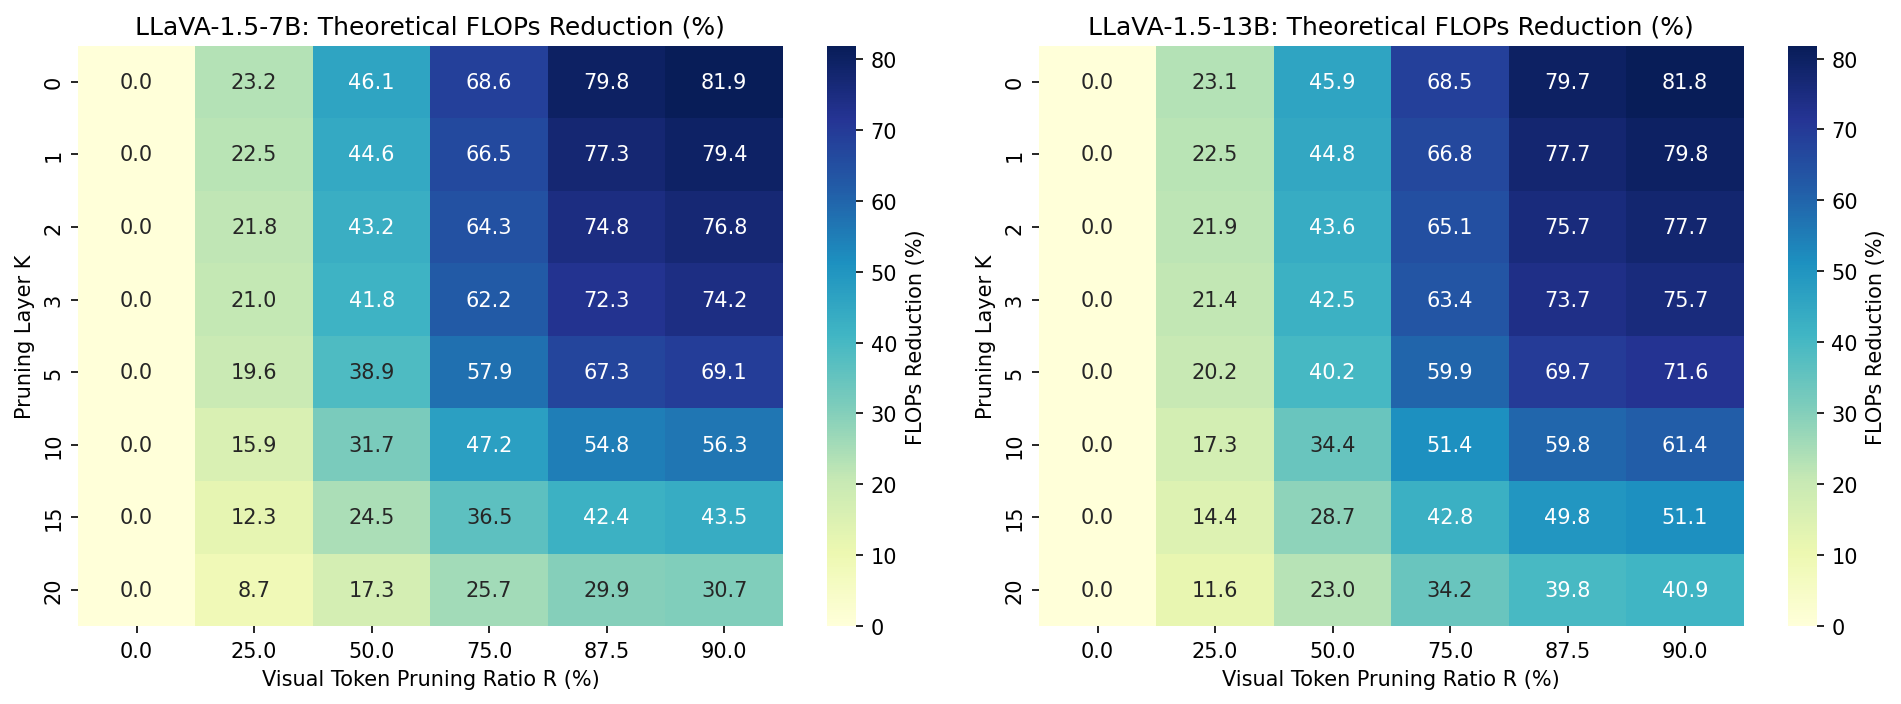

In [6]:
flops_dir = os.path.join(OUTPUT_ROOT, "exp0_flops")
os.makedirs(flops_dir, exist_ok=True)

model_specs = {
    "LLaVA-1.5-7B": dict(num_layers=32, hidden_size=4096, intermediate_size=11008, swiglu=False),
    "LLaVA-1.5-13B": dict(num_layers=40, hidden_size=5120, intermediate_size=13824, swiglu=False),
}
ks_grid = [0, 1, 2, 3, 5, 10, 15, 20]
rs_grid = [0.0, 0.25, 0.50, 0.75, 0.875, 0.90]

rows = []
for mname, spec in model_specs.items():
    for k in ks_grid:
        for r in rs_grid:
            res = compute_fastv_flops_ratio(
                num_layers=spec["num_layers"],
                fastv_k=k,
                fastv_r=r,
                n_image_tokens=576,
                n_text_tokens=60,
                hidden_size=spec["hidden_size"],
                intermediate_size=spec["intermediate_size"],
                swiglu=spec["swiglu"],
            )
            rows.append(
                {
                    "Model": mname,
                    "K": k,
                    "R (%)": round(r * 100, 1),
                    "FLOPs Ratio (%)": round(res["flops_ratio_pct"], 2),
                    "FLOPs Reduction (%)": round(res["flops_reduction_pct"], 2),
                    "Baseline TFLOPs": round(res["baseline_tflops"], 3),
                    "FastV TFLOPs": round(res["fastv_tflops"], 3),
                }
            )

flops_df = pd.DataFrame(rows)
display(flops_df[(flops_df["K"].isin([2, 3])) & (flops_df["R (%)"].isin([0.0, 25.0, 50.0, 75.0, 87.5]))])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)
for ax, mname in zip(axes, model_specs.keys()):
    sub = flops_df[flops_df["Model"] == mname].pivot(index="K", columns="R (%)", values="FLOPs Reduction (%)")
    sns.heatmap(sub, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "FLOPs Reduction (%)"})
    ax.set_title(f"{mname}: Theoretical FLOPs Reduction (%)")
    ax.set_xlabel("Visual Token Pruning Ratio R (%)")
    ax.set_ylabel("Pruning Layer K")

plt.tight_layout()
plt.savefig(os.path.join(flops_dir, "theoretical_flops_heatmap.png"), bbox_inches="tight")
plt.show()
flops_df.to_csv(os.path.join(flops_dir, "theoretical_flops.csv"), index=False)

---
## Section 2 — Load VLM Once & Run Qualitative + Latency Demo Across Scorers

Loads `MODEL_ID` **once** in GPU memory via `load_vlm_model(...)` and compares **Vanilla Decoding**, **Original Paper (`fastv_mean`)**, **Individual Scorers**, and **Normalized Linear Combinations** at $(K=2, R=50\%)$ and $(K=3, R=75\%)$ under both `use_cache=True` (KV-cache pruning) and `use_cache=False` (dynamic re-pruning), confirming zero latency overhead from combined scoring.

In [7]:
print(f"Loading {MODEL_ID} via {HANDLER.name} (quantization={QUANTIZATION}, dtype={DTYPE}) once for all experiments...")
model, processor, controller = load_vlm_model(
    model_id=MODEL_ID,
    handler=HANDLER,
    quantization=QUANTIZATION,
    dtype=DTYPE,
    attn_implementation="eager",
    fastv_config=FastVConfig(use_fastv=False),
    device_map={"": "cuda:0"} if torch.cuda.is_available() else None,
)
DEVICE = next(model.parameters()).device
VIS_TOKEN_IDS = controller.adapter.get_visual_token_ids(model)
IMAGE_TOKEN_INDEX = int(VIS_TOKEN_IDS[0]) if VIS_TOKEN_IDS else 32000
TEXT_CFG = getattr(model.config, "text_config", model.config)
NUM_LAYERS = int(getattr(TEXT_CFG, "num_hidden_layers", 32))
HIDDEN_SIZE = int(getattr(TEXT_CFG, "hidden_size", 4096))
INTERMEDIATE_SIZE = int(getattr(TEXT_CFG, "intermediate_size", 11008))
print(
    f"Loaded on {DEVICE} | adapter={controller.adapter.name} | image_token_id={IMAGE_TOKEN_INDEX} | "
    f"layers={NUM_LAYERS}, hidden={HIDDEN_SIZE}, intermediate={INTERMEDIATE_SIZE}"
)

Loading llava-hf/llava-1.5-7b-hf via llava (quantization=fp16, dtype=torch.float16) once for all experiments...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

... (9 outputs left out)

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

Loaded on cuda:0 | adapter=llava_llama | image_token_id=32000 | layers=32, hidden=4096, intermediate=11008


In [8]:
demo_dir = os.path.join(OUTPUT_ROOT, "exp0_demo")
os.makedirs(demo_dir, exist_ok=True)

demo_img_url = "http://images.cocodataset.org/val2017/000000039769.jpg"
try:
    demo_image = Image.open(BytesIO(requests.get(demo_img_url, timeout=20).content)).convert("RGB")
except Exception:
    demo_image = Image.open(os.path.join(REPO_ROOT, "figs", "example.jpg")).convert("RGB")

demo_prompt = "What are these? Describe the image in details"
demo_inputs, demo_span = prepare_vlm_inputs(
    processor=processor,
    prompt=demo_prompt,
    image=demo_image,
    device=DEVICE,
    dtype=DTYPE,
    handler=HANDLER,
    include_system_prompt=False,
    image_token_index=IMAGE_TOKEN_INDEX,
)
print(f"Prompt length={demo_inputs['input_ids'].shape[1]} | Detected image span={demo_span}")

demo_configs = [
    ("Vanilla (KV-cache=True)", FastVConfig(use_fastv=False), True),
    ("Paper: fastv_mean K=2 R=50% (KV=True)", make_scorer_cfg(SCORER_BY_ID["fastv_mean"], 2, 0.50), True),
    ("Indiv: text_query_mean K=2 R=50% (KV=True)", make_scorer_cfg(SCORER_BY_ID["text_query_mean"], 2, 0.50), True),
    ("Indiv: entropy_weighted K=2 R=50% (KV=True)", make_scorer_cfg(SCORER_BY_ID["entropy_weighted"], 2, 0.50), True),
    ("Indiv: hidden_norm K=2 R=50% (KV=True)", make_scorer_cfg(SCORER_BY_ID["hidden_norm"], 2, 0.50), True),
    ("Combo (Z): mean+text_q+norm K=2 R=50% (KV=True)", make_scorer_cfg(SCORER_BY_ID["combo_mean_text_norm"], 2, 0.50), True),
    ("Paper: fastv_mean K=3 R=75% (KV=True)", make_scorer_cfg(SCORER_BY_ID["fastv_mean"], 3, 0.75), True),
    ("Combo (Z): mean+text_q+norm K=3 R=75% (KV=True)", make_scorer_cfg(SCORER_BY_ID["combo_mean_text_norm"], 3, 0.75), True),
    ("Vanilla (KV-cache=False)", FastVConfig(use_fastv=False), False),
    ("Paper: fastv_mean K=2 R=50% (KV=False)", make_scorer_cfg(SCORER_BY_ID["fastv_mean"], 2, 0.50), False),
    ("Combo (Z): mean+text_q+norm K=2 R=50% (KV=False)", make_scorer_cfg(SCORER_BY_ID["combo_mean_text_norm"], 2, 0.50), False),
    ("Paper: fastv_mean K=3 R=75% (KV=False)", make_scorer_cfg(SCORER_BY_ID["fastv_mean"], 3, 0.75), False),
    ("Combo (Z): mean+text_q+norm K=3 R=75% (KV=False)", make_scorer_cfg(SCORER_BY_ID["combo_mean_text_norm"], 3, 0.75), False),
]

demo_rows = []
demo_outputs = {}
prompt_len = int(demo_inputs["input_ids"].shape[1])
img_len = demo_span[1] if demo_span else 576
txt_len = max(1, prompt_len - img_len)

for label, cfg, use_cache in demo_configs:
    controller.update_config(cfg)
    max_toks = 128 if use_cache else 64
    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    with torch.inference_mode():
        gen = model.generate(
            **demo_inputs,
            min_new_tokens=max_toks,
            max_new_tokens=max_toks,
            do_sample=False,
            use_cache=use_cache,
            return_dict_in_generate=True,
        )
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    peak_mem = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0
    n_gen = int(gen.sequences.shape[1] - prompt_len)
    decoded = processor.tokenizer.decode(gen.sequences[0, prompt_len:], skip_special_tokens=True).strip()
    flops = compute_fastv_flops_ratio(
        NUM_LAYERS, cfg.fastv_k, cfg.fastv_r if cfg.use_fastv else 0.0,
        img_len, txt_len, HIDDEN_SIZE, INTERMEDIATE_SIZE, swiglu=IS_SWIGLU,
    )
    demo_outputs[label] = decoded
    demo_rows.append(
        {
            "Config": label,
            "Scorer": cfg.scorer if cfg.use_fastv else "vanilla",
            "KV-Cache": use_cache,
            "Tokens": n_gen,
            "Total Time (s)": round(elapsed, 3),
            "ms / token": round((elapsed / max(1, n_gen)) * 1000.0, 2),
            "Peak GPU (GiB)": round(peak_mem, 2),
            "FLOPs (%)": round(flops["flops_ratio_pct"], 1),
        }
    )

demo_df = pd.DataFrame(demo_rows)
display(demo_df)
for label in (
    "Vanilla (KV-cache=True)",
    "Paper: fastv_mean K=3 R=75% (KV=True)",
    "Combo (Z): mean+text_q+norm K=3 R=75% (KV=True)",
):
    print(f"\n--- {label} ---\n{demo_outputs[label][:420]}")

demo_df.to_csv(os.path.join(demo_dir, "demo_scorer_benchmark.csv"), index=False)

Prompt length=598 | Detected image span=(5, 576)


,Config,Scorer,KV-Cache,Tokens,Total Time (s),ms / token,Peak GPU (GiB),FLOPs (%)
0,Vanilla (KV-cache=True),vanilla,True,128,9.766,76.30,13.60,100.0
1,Paper: fastv_mean K=2 R=50% (KV=True),fastv_mean,True,128,7.675,59.96,13.79,54.1
2,Indiv: text_query_mean K=2 R=50% (KV=True),text_query_mean,True,128,7.639,59.68,13.66,54.1
3,Indiv: entropy_weighted K=2 R=50% (KV=True),entropy_weighted,True,128,7.722,60.33,13.65,54.1
4,Indiv: hidden_norm K=2 R=50% (KV=True),hidden_norm,True,128,7.675,59.96,13.66,54.1
5,Combo (Z): mean+text_q+norm K=2 R=50% (KV=True),combo_mean_text_norm,True,128,7.661,59.85,13.65,54.1
6,Paper: fastv_mean K=3 R=75% (KV=True),fastv_mean,True,128,7.560,59.06,13.60,34.0
7,Combo (Z): mean+text_q+norm K=3 R=75% (KV=True),combo_mean_text_norm,True,128,7.558,59.05,13.54,34.0
8,Vanilla (KV-cache=False),vanilla,False,64,16.324,255.06,13.51,100.0
9,Paper: fastv_mean K=2 R=50% (KV=False),fastv_mean,False,64,10.378,162.15,13.34,54.1



--- Vanilla (KV-cache=True) ---
The image features two cats lying on a pink couch. One cat is located on the left side of the couch, while the other cat is on the right side. Both cats are sleeping peacefully, with their eyes closed. 

In the scene, there are also two remote controls placed near the cats. One remote is located on the left side of the couch, while the other is on the right side. The presence of the remote controls suggests that the 

--- Paper: fastv_mean K=3 R=75% (KV=True) ---
The image features a pink couch with a remote control placed on it. The remote control is positioned towards the left side of the couch. There are two cats in the scene, one located near the center of the couch and the other towards the right side. The cats appear to be relaxing or sleeping on the couch, creating a cozy and comfortable atmosphere. The presence of the remote control suggests that the couch is in a liv

--- Combo (Z): mean+text_q+norm K=3 R=75% (KV=True) ---
The image features a 

---
## Section 3 — Experiment 1: Attention Inefficiency (Paper Figs 2–3) & Spatial Patch Selection Analysis

### Part 3A — Layer-Wise Visual Attention Efficiency (Paper Figures 2 & 3)
Reproduces the paper's core empirical motivation: visual tokens receive dense attention in Layers 1–2, after which attention collapses onto system/anchor and text tokens.

Generated description (img span=35:611):
The image features a unique and eye-catching toy, resembling a red and orange fire-breathing lion or a flaming horse. The toy is wearing glasses, giving it a quirky and playful appearance. The fire-breathing effect is achieved through the use of bright orange and red colors, which create a striking contrast against the lighter background. The toy is positioned on a table, drawing attention to

Visual Attention Share — Layer 1: 0.610 | Layer 2: 0.246 | Layer 3: 0.081 | Deep Avg (Layers 3..32): 0.086


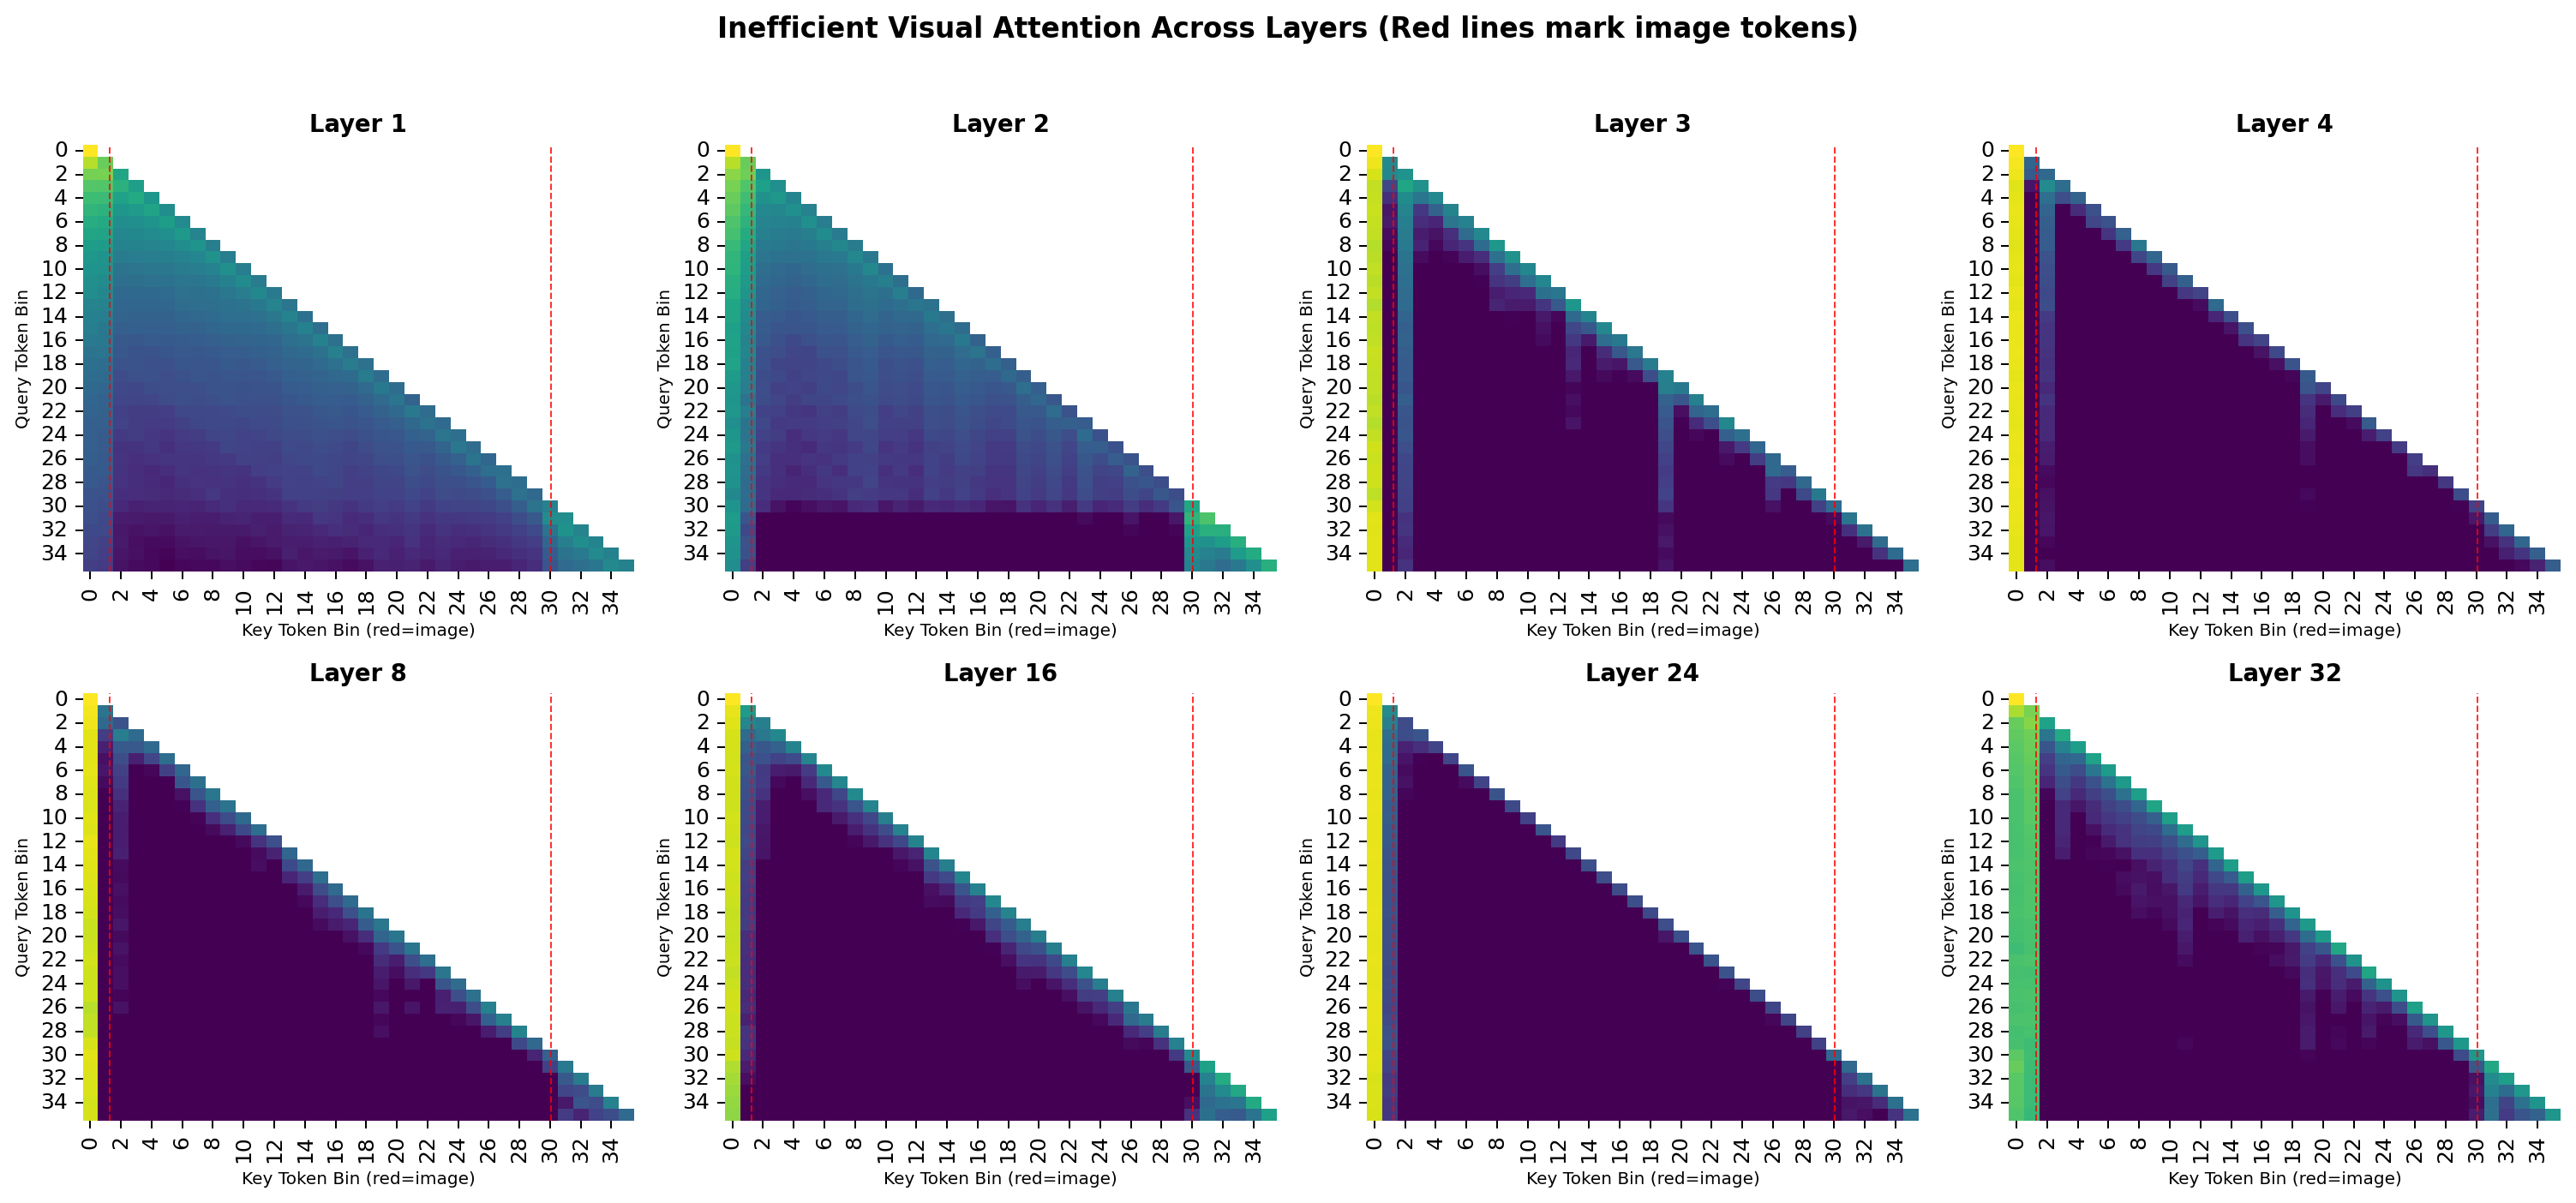

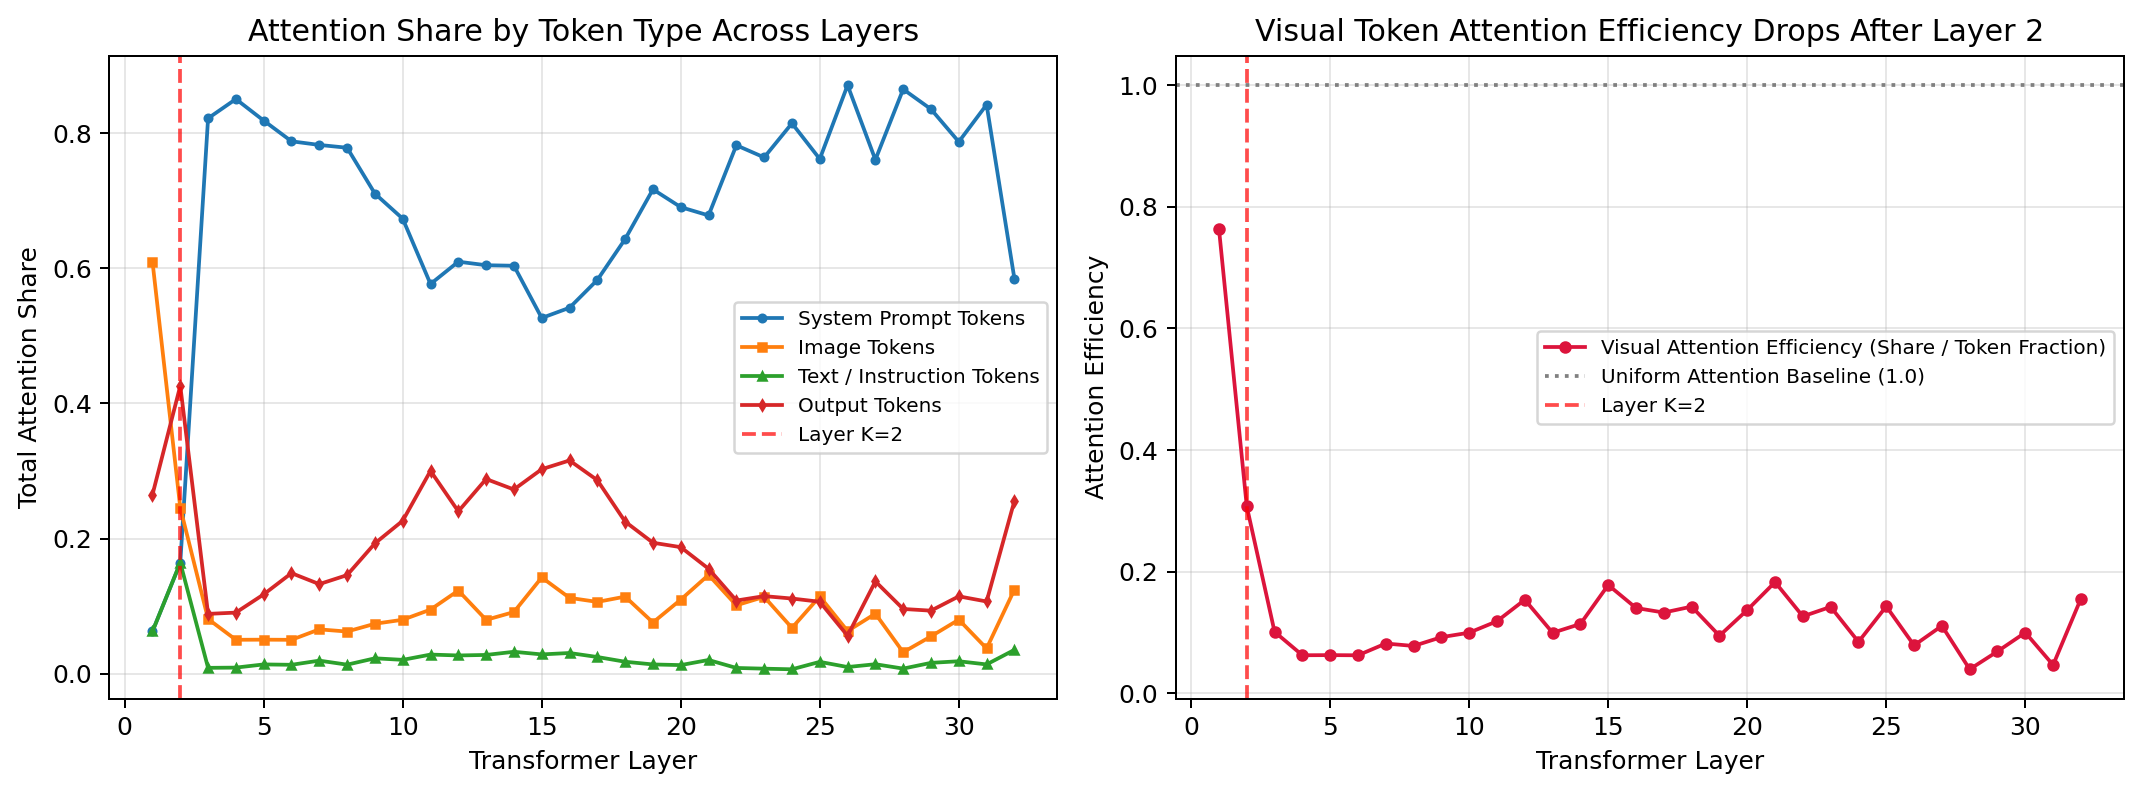

In [9]:
from FastV.inference.plot_inefficient_attention import (
    plot_attention_efficiency,
    plot_attention_grid,
    visualize_attention,
)

exp1_dir = os.path.join(OUTPUT_ROOT, "exp1_attention")
exp1_maps_dir = os.path.join(exp1_dir, "attn_maps")
os.makedirs(exp1_maps_dir, exist_ok=True)

controller.disable()
vis_image_path = os.path.join(REPO_ROOT, "src", "LLaVA", "images", "llava_logo.png")
vis_prompt = "Describe the image in details."
vis_image = Image.open(vis_image_path).convert("RGB")

vis_inputs, vis_span = prepare_vlm_inputs(
    processor=processor,
    prompt=vis_prompt,
    image=vis_image,
    device=DEVICE,
    dtype=DTYPE,
    handler=HANDLER,
    include_system_prompt=True,
    image_token_index=IMAGE_TOKEN_INDEX,
)
vis_prompt_len = int(vis_inputs["input_ids"].shape[1])
vis_img_start, vis_img_len = vis_span if vis_span else (35, 576)

with torch.inference_mode():
    vis_gen = model.generate(
        **vis_inputs,
        do_sample=False,
        max_new_tokens=96,
        use_cache=True,
        return_dict_in_generate=True,
    )
vis_output_text = processor.tokenizer.decode(
    vis_gen.sequences[0, vis_prompt_len:], skip_special_tokens=True
).strip()
print(f"Generated description (img span={vis_img_start}:{vis_img_start + vis_img_len}):\n{vis_output_text}\n")

append_str = (" " + vis_output_text) if HANDLER.name == "llava" else vis_output_text
full_vis_inputs, _ = prepare_vlm_inputs(
    processor=processor,
    prompt=vis_prompt,
    image=vis_image,
    device=DEVICE,
    dtype=DTYPE,
    handler=HANDLER,
    include_system_prompt=True,
    append_output=append_str,
    image_token_index=IMAGE_TOKEN_INDEX,
)
with torch.inference_mode():
    fwd_out = model(**full_vis_inputs, output_attentions=True, use_cache=False, return_dict=True)

attentions_cpu = [a.detach().cpu() for a in fwd_out.attentions]
del fwd_out, vis_inputs, full_vis_inputs, vis_gen
if torch.cuda.is_available():
    torch.cuda.empty_cache()

efficiency = compute_layer_attention_efficiency(
    attentions=attentions_cpu,
    image_start=vis_img_start,
    image_length=vis_img_len,
    instruction_end=vis_prompt_len,
)

grid_path = os.path.join(exp1_dir, "attn_grid.png")
eff_path = os.path.join(exp1_dir, "attention_efficiency.png")
plot_attention_grid(attentions_cpu, grid_path, image_start=vis_img_start, image_length=vis_img_len)
plot_attention_efficiency(efficiency, eff_path)

for l_idx in [0, 1, 2, 4, 9, 19, len(attentions_cpu) - 1]:
    if l_idx < len(attentions_cpu):
        visualize_attention(
            attentions_cpu[l_idx],
            output_path=os.path.join(exp1_maps_dir, f"atten_map_{l_idx}.png"),
            title=f"Layer {l_idx + 1}",
            image_start=vis_img_start,
            image_length=vis_img_len,
        )

with open(os.path.join(exp1_dir, "attention_efficiency.json"), "w") as f:
    json.dump(efficiency, f, indent=2)

eff_df = pd.DataFrame(efficiency)
print(
    f"Visual Attention Share — Layer 1: {eff_df.loc[0, 'image_total']:.3f} | "
    f"Layer 2: {eff_df.loc[1, 'image_total']:.3f} | "
    f"Layer 3: {eff_df.loc[2, 'image_total']:.3f} | "
    f"Deep Avg (Layers 3..{len(eff_df)}): {eff_df.loc[2:, 'image_total'].mean():.3f}"
)
display(IPyImage(filename=grid_path))
display(IPyImage(filename=eff_path))
del attentions_cpu

### Part 3B — Spatial Patch Keep-Masks & Pairwise Scorer Overlap / Correlation Diagnostics

Inspects **which exact visual patches** survive pruning at Layer $K=2, R=75\%$ (top 25% patches kept) across all individual and combined scorers on a question-answering prompt:
1. **Spatial Patch Keep-Masks**: Overlays kept patches onto the image for `fastv_mean` (Paper) vs `text_query_mean` vs `entropy_weighted` vs `hidden_norm` vs linear combinations.
2. **Pairwise Jaccard IoU & Spearman Rank Correlation**: Quantifies how complementary the alternative signals are relative to `fastv_mean` and how normalized linear combinations blend them.

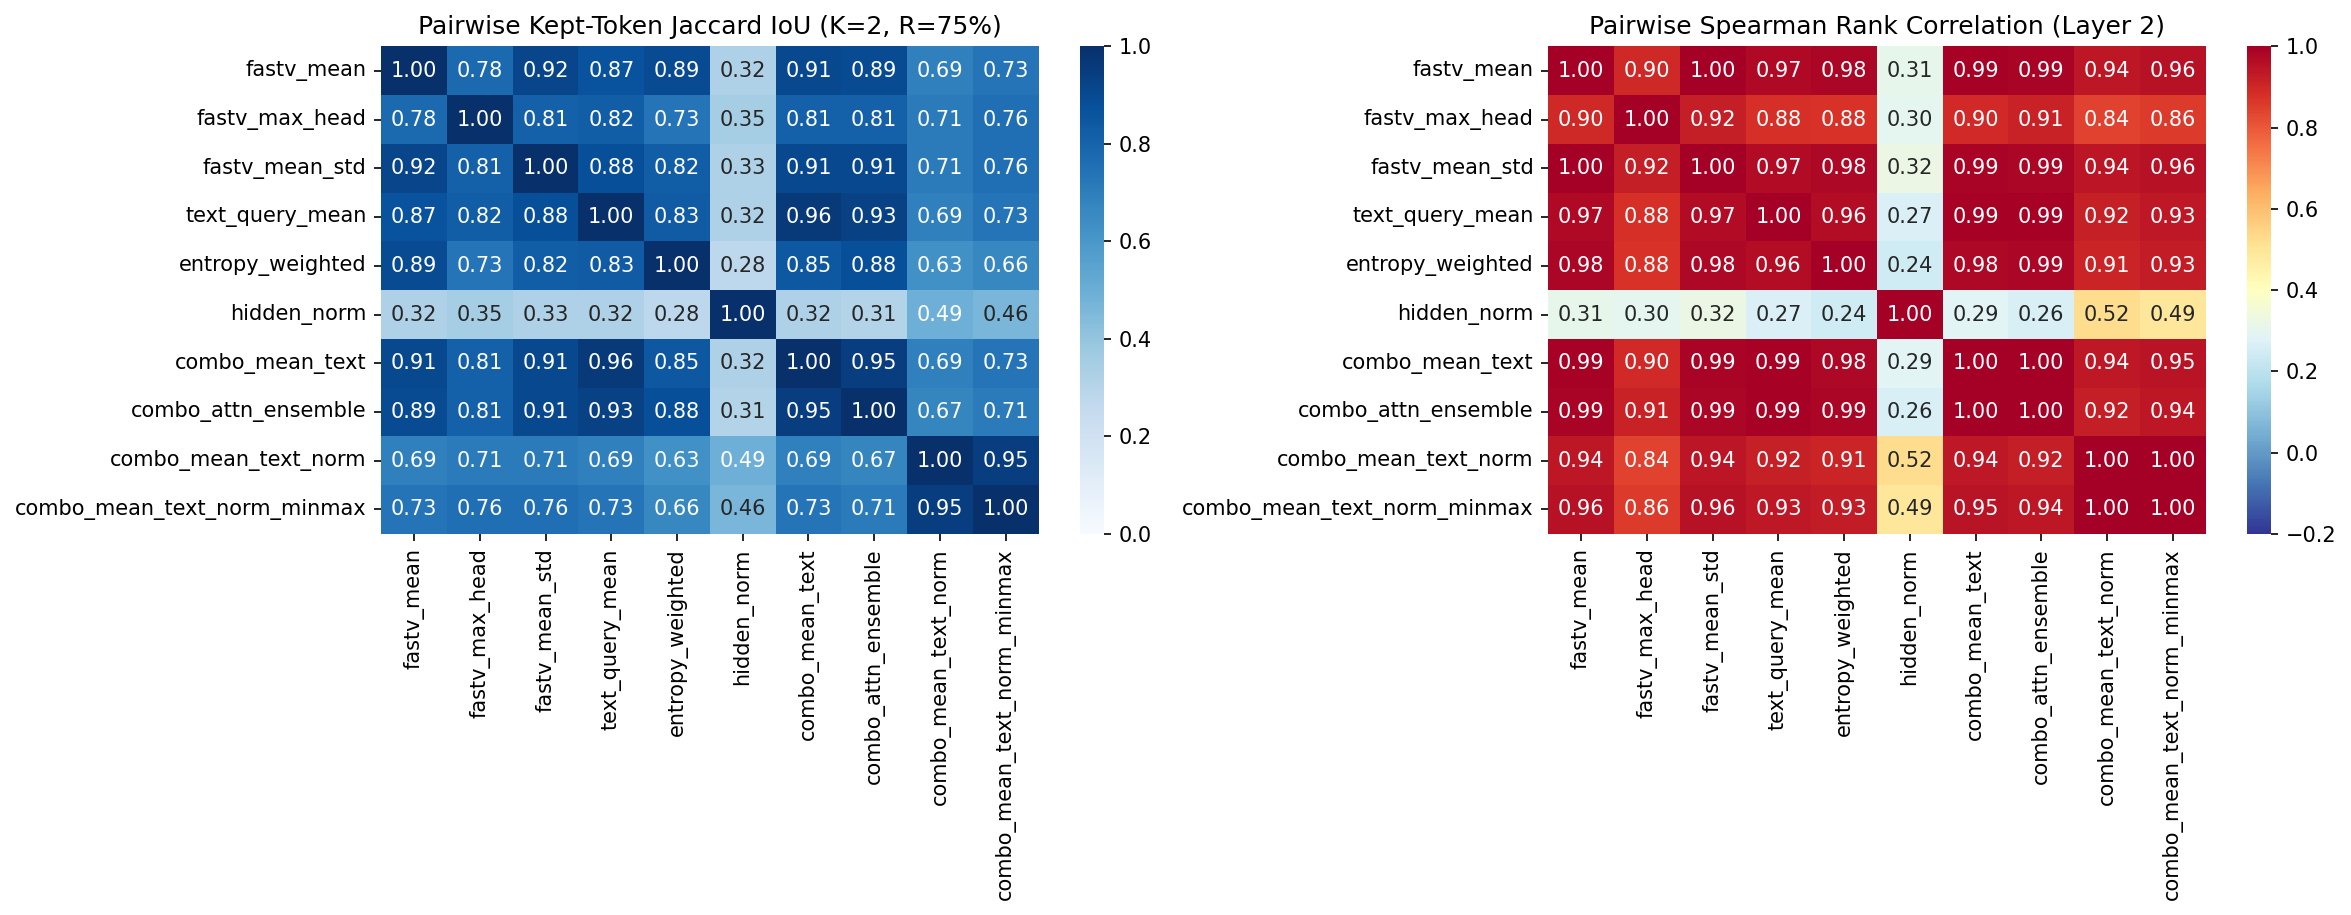

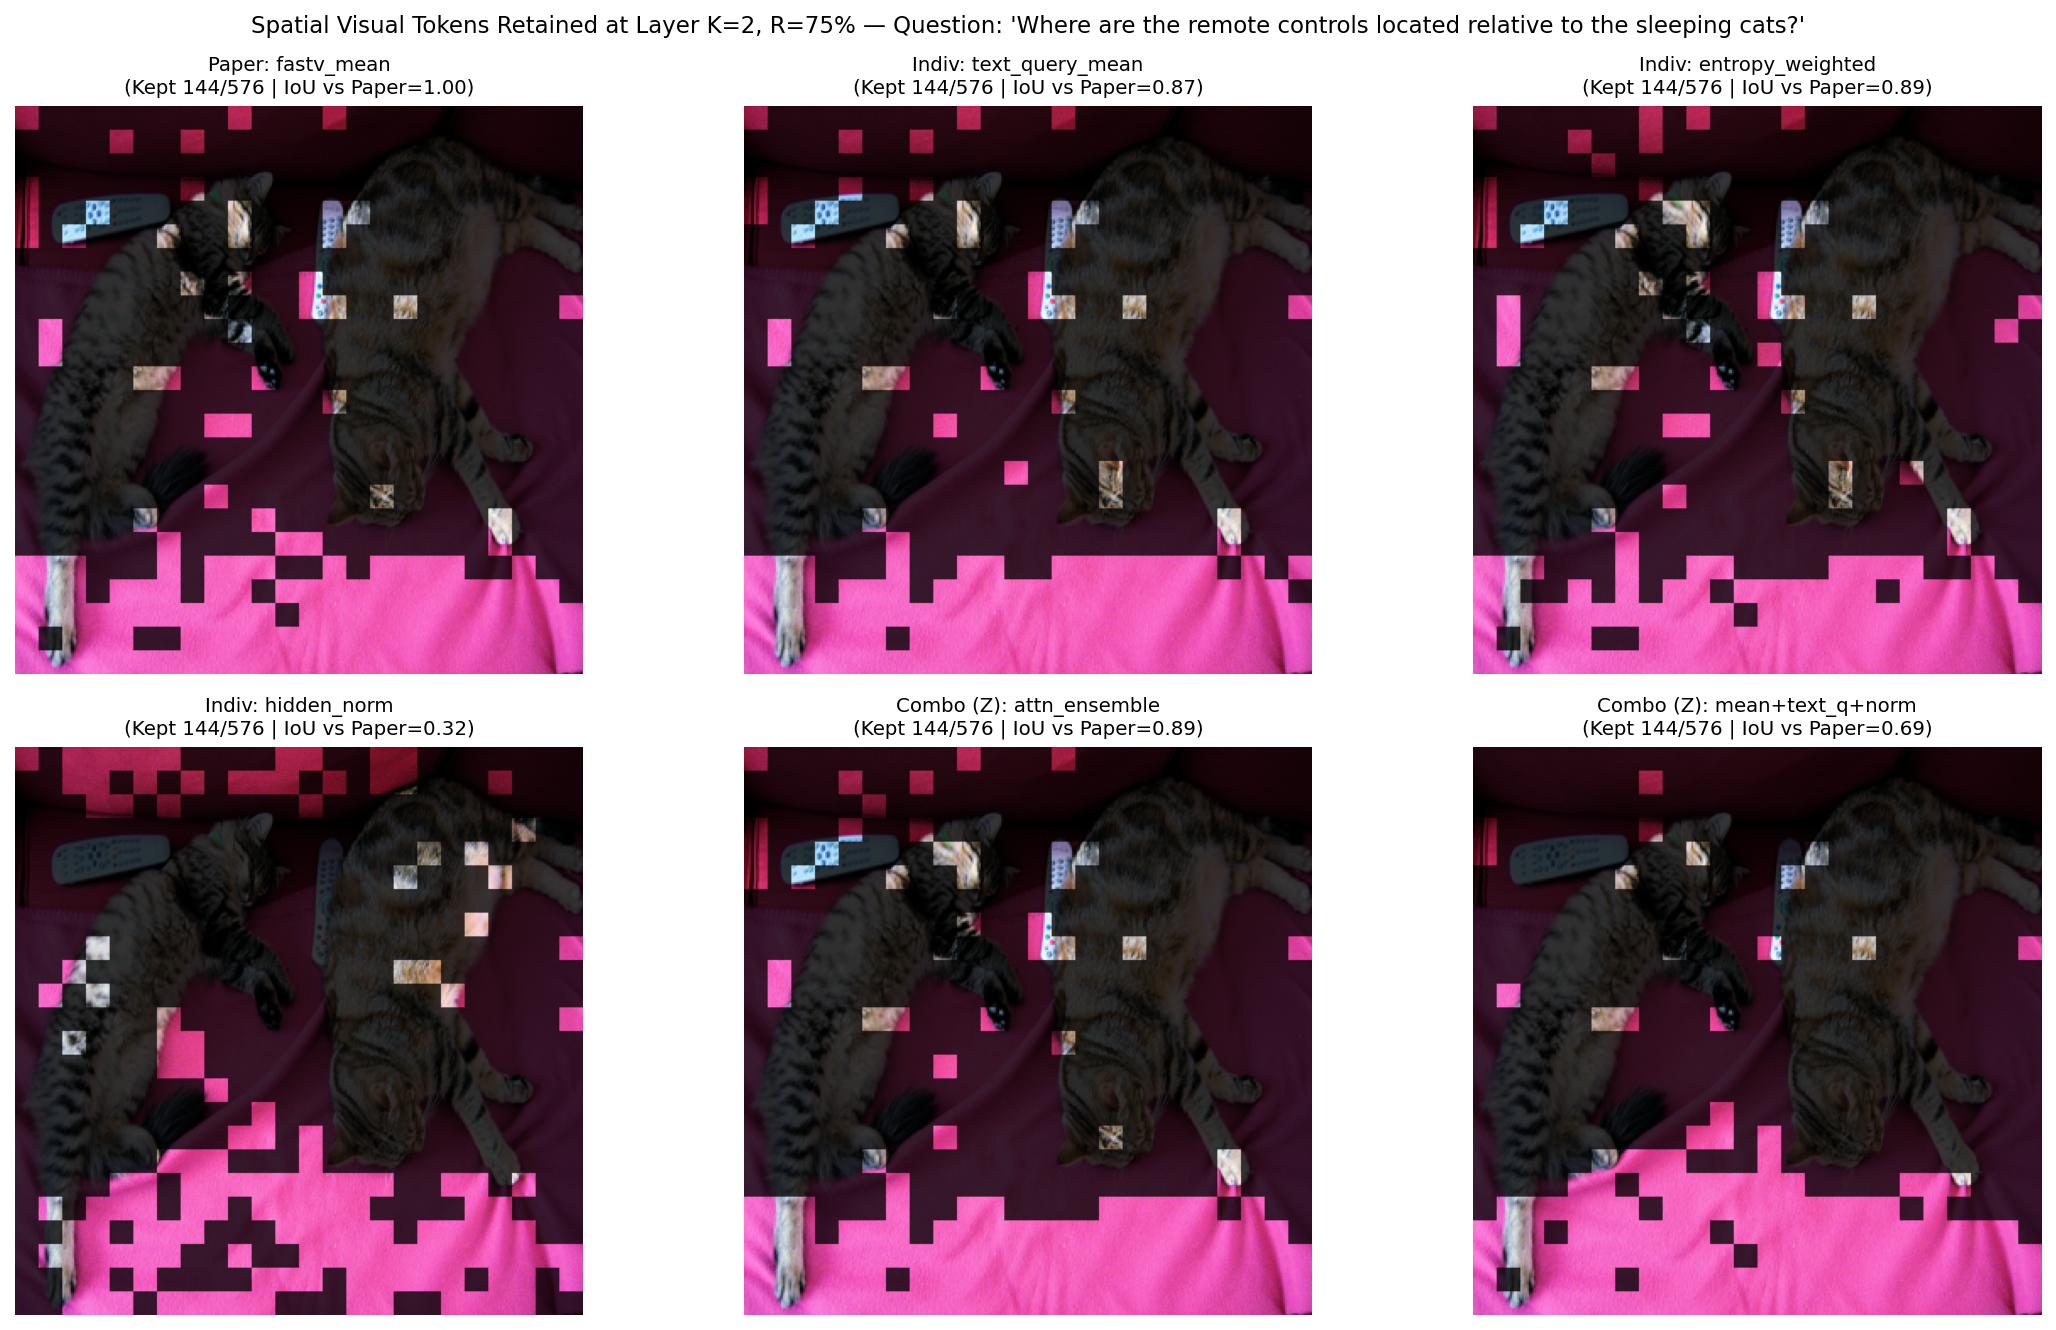

In [10]:
controller.disable()
diag_question = "Where are the remote controls located relative to the sleeping cats?"
diag_inputs, diag_span = prepare_vlm_inputs(
    processor=processor,
    prompt=diag_question,
    image=demo_image,
    device=DEVICE,
    dtype=DTYPE,
    handler=HANDLER,
    include_system_prompt=True,
    image_token_index=IMAGE_TOKEN_INDEX,
)

k_diag = 2
r_diag = 0.75
detected_vis = detect_visual_token_indices(
    diag_inputs["input_ids"],
    visual_token_ids=VIS_TOKEN_IDS,
    default_image_length=controller.default_image_length,
)
if detected_vis:
    diag_len = len(detected_vis)
    vis_idx_tensor = torch.tensor(detected_vis, dtype=torch.long, device=DEVICE)
else:
    diag_start, diag_len = diag_span if diag_span else (35, 576)
    vis_idx_tensor = torch.arange(diag_start, diag_start + diag_len, dtype=torch.long, device=DEVICE)

# Capture Layer K input hidden_states directly via pre-hook so every transformers 4.x/5.x layout works
_captured_diag_hs = {}
def _capture_k_hs(_mod, args, kwargs):
    hs = args[0] if (len(args) > 0 and torch.is_tensor(args[0])) else kwargs.get("hidden_states")
    if hs is not None:
        _captured_diag_hs["hs"] = hs.detach()

_diag_hook = controller.backbone.layers[k_diag].register_forward_pre_hook(_capture_k_hs, with_kwargs=True)
try:
    with torch.inference_mode():
        diag_fwd = model(
            **diag_inputs,
            output_attentions=True,
            use_cache=False,
            return_dict=True,
        )
finally:
    _diag_hook.remove()

# Layer K-1 attention weights and Layer K input hidden states (matching FastVController at idx == K)
layer_k_minus_1_attn = diag_fwd.attentions[k_diag - 1].detach()
layer_k_input_hs = _captured_diag_hs["hs"]

keep_k = max(1, int(round(diag_len * (1.0 - r_diag))))
scorer_raw_vectors = {}
scorer_top_sets = {}

for spec in ALL_BENCHMARK_SCORERS:
    sc_vec = score_visual_tokens(
        spec["scorer"],
        layer_k_minus_1_attn,
        vis_idx_tensor,
        hidden_states=layer_k_input_hs,
        **spec.get("scorer_kwargs", {}),
    ).detach().cpu().float()
    scorer_raw_vectors[spec["id"]] = sc_vec.numpy()
    scorer_top_sets[spec["id"]] = set(sc_vec.topk(keep_k).indices.tolist())

del diag_fwd, layer_k_minus_1_attn, layer_k_input_hs, diag_inputs
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 1. Compute Pairwise Jaccard Overlap (at R=75%) & Spearman Rank Correlation across all 10 scorers
scorer_ids = [s["id"] for s in ALL_BENCHMARK_SCORERS]
jaccard_mat = np.zeros((len(scorer_ids), len(scorer_ids)), dtype=float)
spearman_mat = np.zeros((len(scorer_ids), len(scorer_ids)), dtype=float)

for i, id_a in enumerate(scorer_ids):
    ra = pd.Series(scorer_raw_vectors[id_a]).rank()
    set_a = scorer_top_sets[id_a]
    for j, id_b in enumerate(scorer_ids):
        rb = pd.Series(scorer_raw_vectors[id_b]).rank()
        set_b = scorer_top_sets[id_b]
        union_n = len(set_a | set_b)
        jaccard_mat[i, j] = len(set_a & set_b) / float(max(1, union_n))
        spearman_mat[i, j] = float(ra.corr(rb))

fig, (ax_j, ax_s) = plt.subplots(1, 2, figsize=(16, 6.2), dpi=150)
sns.heatmap(
    pd.DataFrame(jaccard_mat, index=scorer_ids, columns=scorer_ids),
    annot=True, fmt=".2f", cmap="Blues", vmin=0.0, vmax=1.0, ax=ax_j,
)
ax_j.set_title(f"Pairwise Kept-Token Jaccard IoU (K={k_diag}, R={int(r_diag*100)}%)")

sns.heatmap(
    pd.DataFrame(spearman_mat, index=scorer_ids, columns=scorer_ids),
    annot=True, fmt=".2f", cmap="RdYlBu_r", vmin=-0.2, vmax=1.0, ax=ax_s,
)
ax_s.set_title(f"Pairwise Spearman Rank Correlation (Layer {k_diag})")
plt.tight_layout()
plt.savefig(os.path.join(exp1_dir, "scorer_overlap_and_correlation.png"), bbox_inches="tight")
plt.show()

# 2. Render 2D Spatial Patch Keep-Masks overlaid on the input image
def _infer_grid_hw(n_tokens: int, img_w: int, img_h: int):
    root = int(round(math.sqrt(n_tokens)))
    if root * root == n_tokens:
        return root, root
    target_ratio = img_h / max(1.0, float(img_w))
    best_hw = (1, n_tokens)
    best_err = float("inf")
    for h in range(1, int(math.sqrt(n_tokens)) + 1):
        if n_tokens % h == 0:
            w = n_tokens // h
            for ch, cw in ((h, w), (w, h)):
                err = abs((ch / float(cw)) - target_ratio)
                if err < best_err:
                    best_err = err
                    best_hw = (ch, cw)
    return best_hw


grid_h, grid_w = _infer_grid_hw(diag_len, demo_image.width, demo_image.height)
panel_ids = [
    ("fastv_mean", "Paper: fastv_mean"),
    ("text_query_mean", "Indiv: text_query_mean"),
    ("entropy_weighted", "Indiv: entropy_weighted"),
    ("hidden_norm", "Indiv: hidden_norm"),
    ("combo_attn_ensemble", "Combo (Z): attn_ensemble"),
    ("combo_mean_text_norm", "Combo (Z): mean+text_q+norm"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9), dpi=150)
base_resized = np.asarray(demo_image.resize((grid_w * 14, grid_h * 14))) / 255.0

for ax, (sid, title) in zip(axes.flat, panel_ids):
    mask_1d = np.zeros(diag_len, dtype=np.float32)
    for idx_kept in scorer_top_sets[sid]:
        mask_1d[idx_kept] = 1.0
    mask_2d = mask_1d.reshape(grid_h, grid_w)
    mask_up = np.kron(mask_2d, np.ones((14, 14), dtype=np.float32))[..., None]
    # Dim dropped patches to 22% brightness, highlight kept patches at 100%
    blended = np.clip(base_resized * (0.22 + 0.78 * mask_up), 0.0, 1.0)
    iou_vs_paper = len(scorer_top_sets[sid] & scorer_top_sets["fastv_mean"]) / float(
        max(1, len(scorer_top_sets[sid] | scorer_top_sets["fastv_mean"]))
    )
    ax.imshow(blended)
    ax.set_title(f"{title}\n(Kept {keep_k}/{diag_len} | IoU vs Paper={iou_vs_paper:.2f})", fontsize=9.5)
    ax.axis("off")

plt.suptitle(f"Spatial Visual Tokens Retained at Layer K={k_diag}, R={int(r_diag*100)}% — Question: '{diag_question}'", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(exp1_dir, "spatial_patch_selection_comparison.png"), bbox_inches="tight")
plt.show()

---
## Section 4 — Experiment 2: A-OKVQA Accuracy, Latency, VRAM & Combination Sweep (Paper Table 4)

### Part 4A — Multi-Scorer & Linear Combination Benchmark across Pruning Ratios $R$
Evaluates **Vanilla ($R=0\%$)**, **Random Pruning ($K=0$)**, **Original Paper (`fastv_mean`)**, **5 Alternative Individual Scorers**, and **4 Normalized Linear Combinations** on `./data/aokvqa/validation` (`mode="inplace"`, `use_cache=False`, $K=2$, matching `eval_aokvqa_latency_fastv_inplace.sh`), reporting:
* **Accuracy (%)** and exact **$\Delta$ vs. Paper (`fastv_mean`)** at each pruning ratio $R \in \{25\%, 50\%, 75\%, 87.5\%\}$
* **Real Time-to-First-Token Latency (s)**, **Speedup ($\times$)**, **Peak GPU Memory (GiB)**, and **Published Paper Reference Comparison**

Loaded 100 A-OKVQA validation samples.


A-OKVQA Vanilla (R=0%):   0%|          | 0/100 [00:00<?, ?it/s]

Vanilla Baseline: Acc=77.00% | Latency=0.3197s | Peak GPU=13.36 GiB


A-OKVQA Random K=0 R=25.0%:   0%|          | 0/100 [00:00<?, ?it/s]

A-OKVQA fastv_mean K=2 R=25.0%:   0%|          | 0/100 [00:00<?, ?it/s]

A-OKVQA fastv_max_head K=2 R=25.0%:   0%|          | 0/100 [00:00<?, ?it/s]

... (41 outputs left out)


=== A-OKVQA Accuracy (%) Pivot: Scorers vs Pruning Ratio R (K=2, Inplace) ===


R (%),25.0,50.0,75.0,87.5,Mean Acc across R (%),Avg Delta vs Paper (%)
Scorer,,,,,,
Random Pruning (K=0),76.0,75.0,75.0,68.0,73.50,1.50
Combo (Z): 0.4*ent + 0.4*text_q + 0.2*max,76.0,75.0,72.0,70.0,73.25,1.25
Combo (Z): 0.5*mean + 0.5*text_q,76.0,74.0,72.0,69.0,72.75,0.75
Indiv: text_query_mean,76.0,74.0,71.0,70.0,72.75,0.75
Indiv: fastv_max_head,75.0,75.0,72.0,69.0,72.75,0.75
Combo (Z): 0.4*mean + 0.35*text_q + 0.25*norm,76.0,73.0,71.0,70.0,72.50,0.50
Combo (MinMax): 0.4*mean + 0.35*text_q + 0.25*norm,76.0,74.0,71.0,69.0,72.50,0.50
Indiv: entropy_weighted,76.0,73.0,72.0,68.0,72.25,0.25
Paper: fastv_mean,76.0,74.0,71.0,67.0,72.00,0.00



=== Published FastV Paper / Official README A-OKVQA Reference Table ===


,Model,Score (%),Latency A100 (s),GPU Mem (GB)
0,LLaVA-1.5-7B Vanilla (FP16),76.8,0.138,18
1,LLaVA-1.5-13B Vanilla (FP16),81.9,0.203,33
2,LLaVA-1.5-13B FastV K=2 R=25% (FP16),81.8,0.181,29
3,LLaVA-1.5-13B FastV K=2 R=50% (FP16),81.3,0.155,28
4,LLaVA-1.5-13B FastV K=2 R=75% (FP16),80.9,0.124,27
5,LLaVA-1.5-13B Vanilla (4-Bit),81.5,0.308,12
6,LLaVA-1.5-13B FastV K=2 R=25% (4-Bit),81.7,0.277,11
7,LLaVA-1.5-13B FastV K=2 R=50% (4-Bit),81.1,0.275,10
8,LLaVA-1.5-13B FastV K=2 R=75% (4-Bit),80.3,0.245,9


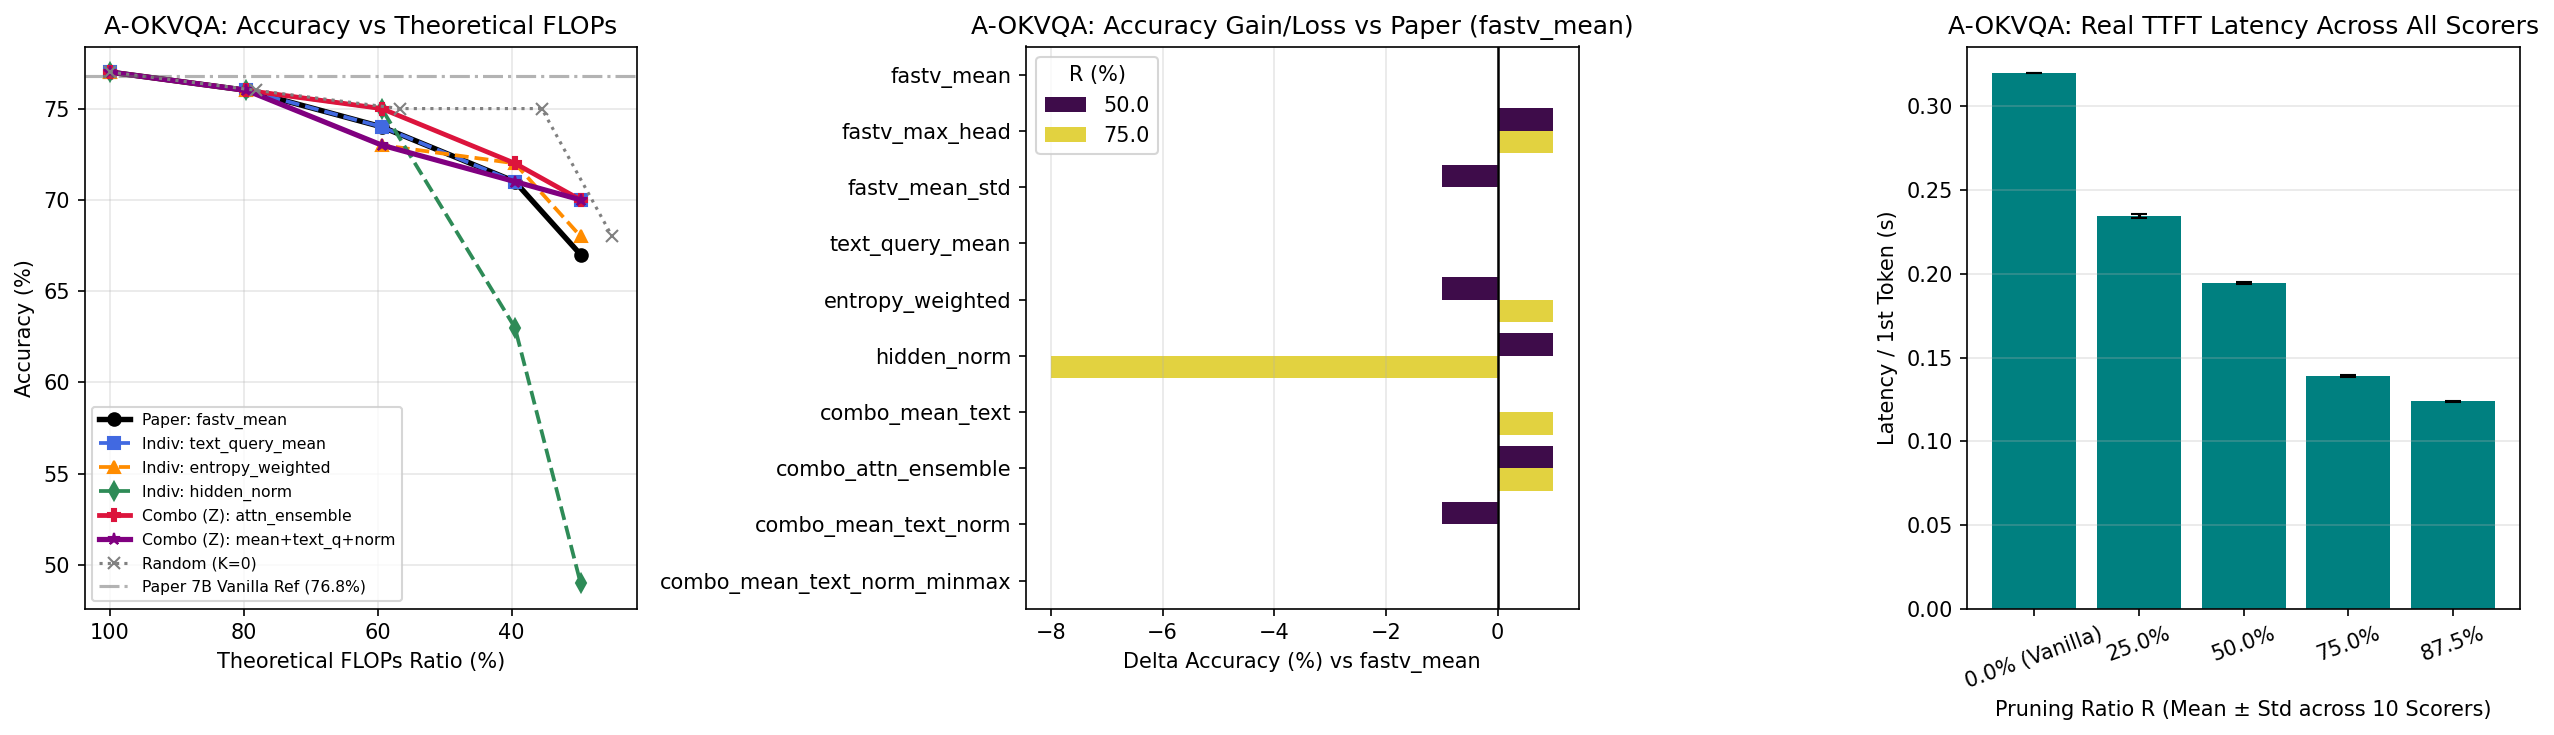

In [11]:
from FastV.inference.eval.inference_aokvqa import (
    TEMPLATE as AOKVQA_TEMPLATE,
    compute_acc as aokvqa_compute_acc,
    format_answer as aokvqa_format_answer,
    format_choices as aokvqa_format_choices,
    load_aokvqa_dataset,
)

exp2_dir = os.path.join(OUTPUT_ROOT, "exp2_aokvqa")
os.makedirs(exp2_dir, exist_ok=True)

aokvqa_ds = load_aokvqa_dataset(os.path.join(REPO_ROOT, "data", "aokvqa", "validation"))
if AOKVQA_MAX_SAMPLES is not None and AOKVQA_MAX_SAMPLES < len(aokvqa_ds):
    aokvqa_ds = aokvqa_ds.select(range(AOKVQA_MAX_SAMPLES))

aok_images = aokvqa_ds["image"]
aok_prompts = [
    AOKVQA_TEMPLATE.format(question=q, options=aokvqa_format_choices(c))
    for q, c in zip(aokvqa_ds["question"], aokvqa_ds["choices"])
]
aok_labels = [aokvqa_format_answer(idx) for idx in aokvqa_ds["correct_choice_idx"]]
print(f"Loaded {len(aok_prompts)} A-OKVQA validation samples.")


def eval_aokvqa_single(cfg: FastVConfig, desc: str, warmup: int = 3):
    controller.update_config(cfg)
    preds, lats, plens, ilens = [], [], [], []
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    eff_warmup = min(warmup, max(0, len(aok_prompts) - 1))
    for idx, (prompt, img) in enumerate(tqdm(zip(aok_prompts, aok_images), total=len(aok_prompts), desc=desc, leave=False)):
        inp, span = prepare_vlm_inputs(
            processor=processor,
            prompt=prompt,
            image=img,
            device=DEVICE,
            dtype=DTYPE,
            handler=HANDLER,
            include_system_prompt=True,
            image_token_index=IMAGE_TOKEN_INDEX,
        )
        plen = int(inp["input_ids"].shape[1])
        plens.append(plen)
        if span is not None:
            ilens.append(int(span[1]))
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.inference_mode():
            gen = model.generate(
                **inp,
                do_sample=False,
                max_new_tokens=1,
                use_cache=False,
                return_dict_in_generate=True,
            )
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        if idx >= eff_warmup:
            lats.append(dt)
        dec = processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip()
        preds.append(dec)

    acc_pct = aokvqa_compute_acc(preds, aok_labels) * 100.0
    avg_lat = float(np.mean(lats)) if lats else 0.0
    peak_mem = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0
    avg_img = max(1, int(round(np.mean(ilens)))) if ilens else 576
    avg_txt = max(1, int(round(np.mean(plens) - avg_img)))
    return acc_pct, avg_lat, peak_mem, avg_img, avg_txt


# 1. Vanilla Baseline (R = 0%)
aok_base_acc, aok_base_lat, aok_base_mem, aok_avg_img, aok_avg_txt = eval_aokvqa_single(
    FastVConfig(use_fastv=False), "A-OKVQA Vanilla (R=0%)"
)
print(f"Vanilla Baseline: Acc={aok_base_acc:.2f}% | Latency={aok_base_lat:.4f}s | Peak GPU={aok_base_mem:.2f} GiB")

aok_rows = [
    {
        "Scorer ID": "vanilla",
        "Scorer": "Vanilla Baseline (R=0%)",
        "Family": "Baseline",
        "K": "-",
        "R (%)": 0.0,
        "Accuracy (%)": round(aok_base_acc, 2),
        "Latency / 1st Token (s)": round(aok_base_lat, 4),
        "Speedup (x)": 1.00,
        "Peak GPU (GiB)": round(aok_base_mem, 2),
        "FLOPs (%)": 100.0,
    }
]

# 2. Random Pruning Baseline (K=0, inplace) + All Benchmark Scorers at K=2
for r in AOKVQA_RS:
    r_pct = round(r * 100.0, 1)
    # Random K=0 baseline
    rnd_cfg = FastVConfig(use_fastv=True, fastv_k=0, fastv_r=r, mode="inplace", random_seed=42)
    rnd_acc, rnd_lat, rnd_mem, _, _ = eval_aokvqa_single(rnd_cfg, f"A-OKVQA Random K=0 R={r_pct}%")
    rnd_flops = compute_fastv_flops_ratio(
        NUM_LAYERS, 0, r, aok_avg_img, aok_avg_txt, HIDDEN_SIZE, INTERMEDIATE_SIZE, swiglu=IS_SWIGLU
    )
    aok_rows.append(
        {
            "Scorer ID": "random_k0",
            "Scorer": "Random Pruning (K=0)",
            "Family": "Random Baseline",
            "K": 0,
            "R (%)": r_pct,
            "Accuracy (%)": round(rnd_acc, 2),
            "Latency / 1st Token (s)": round(rnd_lat, 4),
            "Speedup (x)": round(aok_base_lat / max(1e-6, rnd_lat), 2),
            "Peak GPU (GiB)": round(rnd_mem, 2),
            "FLOPs (%)": round(rnd_flops["flops_ratio_pct"], 1),
        }
    )

    for spec in BENCHMARK_SCORERS:
        cfg = make_scorer_cfg(spec, k=2, r=r, mode="inplace")
        acc, lat, mem, _, _ = eval_aokvqa_single(cfg, f"A-OKVQA {spec['id']} K=2 R={r_pct}%")
        r_eff = cfg.effective_pruning_ratio(aok_avg_img)
        flops = compute_fastv_flops_ratio(
            NUM_LAYERS, 2, r_eff, aok_avg_img, aok_avg_txt, HIDDEN_SIZE, INTERMEDIATE_SIZE, swiglu=IS_SWIGLU
        )
        aok_rows.append(
            {
                "Scorer ID": spec["id"],
                "Scorer": spec["label"],
                "Family": spec["family"],
                "K": 2,
                "R (%)": r_pct,
                "Accuracy (%)": round(acc, 2),
                "Latency / 1st Token (s)": round(lat, 4),
                "Speedup (x)": round(aok_base_lat / max(1e-6, lat), 2),
                "Peak GPU (GiB)": round(mem, 2),
                "FLOPs (%)": round(flops["flops_ratio_pct"], 1),
            }
        )

aok_df = pd.DataFrame(aok_rows)

# Compute exact Delta vs Original Paper Scorer (fastv_mean) at each pruning ratio R
paper_aok_by_r = (
    aok_df[aok_df["Scorer ID"] == "fastv_mean"].set_index("R (%)")["Accuracy (%)"].to_dict()
)
aok_df["Delta vs Paper fastv_mean (%)"] = aok_df.apply(
    lambda row: round(row["Accuracy (%)"] - paper_aok_by_r[row["R (%)"]], 2)
    if row["R (%)"] in paper_aok_by_r
    else 0.0,
    axis=1,
)

print("\n=== A-OKVQA Accuracy (%) Pivot: Scorers vs Pruning Ratio R (K=2, Inplace) ===")
aok_acc_pivot = aok_df[aok_df["R (%)"] > 0].pivot(index="Scorer", columns="R (%)", values="Accuracy (%)")
aok_acc_pivot["Mean Acc across R (%)"] = aok_acc_pivot.mean(axis=1).round(2)
paper_mean_r = float(aok_acc_pivot.loc["Paper: fastv_mean", "Mean Acc across R (%)"])
aok_acc_pivot["Avg Delta vs Paper (%)"] = (aok_acc_pivot["Mean Acc across R (%)"] - paper_mean_r).round(2)
aok_acc_pivot = aok_acc_pivot.sort_values("Mean Acc across R (%)", ascending=False)
display(aok_acc_pivot)

print("\n=== Published FastV Paper / Official README A-OKVQA Reference Table ===")
display(pd.DataFrame(PAPER_REFERENCE["aokvqa_readme_table"]))

aok_df.to_csv(os.path.join(exp2_dir, "aokvqa_scorers_full.csv"), index=False)
aok_acc_pivot.to_csv(os.path.join(exp2_dir, "aokvqa_scorers_pivot.csv"))
with open(os.path.join(exp2_dir, "aokvqa_scorers_full.json"), "w") as f:
    json.dump(aok_df.to_dict(orient="records"), f, indent=2)

# Plot Pareto Frontier & Delta vs Paper fastv_mean
fig, axes = plt.subplots(1, 3, figsize=(17, 5.0), dpi=150)

plot_highlight_ids = [
    ("fastv_mean", "Paper: fastv_mean", "black", "-o", 2.6),
    ("text_query_mean", "Indiv: text_query_mean", "royalblue", "--s", 1.8),
    ("entropy_weighted", "Indiv: entropy_weighted", "darkorange", "--^", 1.8),
    ("hidden_norm", "Indiv: hidden_norm", "seagreen", "--d", 1.8),
    ("combo_attn_ensemble", "Combo (Z): attn_ensemble", "crimson", "-P", 2.3),
    ("combo_mean_text_norm", "Combo (Z): mean+text_q+norm", "purple", "-*", 2.5),
    ("random_k0", "Random (K=0)", "gray", ":x", 1.5),
]
for sid, lbl, col, style, lw in plot_highlight_ids:
    sub = aok_df[aok_df["Scorer ID"] == sid]
    if not sub.empty:
        pts_x = [100.0] + sub["FLOPs (%)"].tolist()
        pts_y = [aok_base_acc] + sub["Accuracy (%)"].tolist()
        axes[0].plot(pts_x, pts_y, style, color=col, linewidth=lw, label=lbl, markersize=6)

axes[0].axhline(76.8, color="dimgray", linestyle="-.", alpha=0.5, label="Paper 7B Vanilla Ref (76.8%)")
axes[0].set_title("A-OKVQA: Accuracy vs Theoretical FLOPs")
axes[0].set_xlabel("Theoretical FLOPs Ratio (%)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].invert_xaxis()
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=7.5)

# Panel 2: Delta vs Paper fastv_mean at R=50% and R=75%
sub_delta = aok_df[(aok_df["R (%)"].isin([50.0, 75.0])) & (aok_df["Scorer ID"] != "random_k0")]
sns.barplot(
    data=sub_delta,
    y="Scorer ID",
    x="Delta vs Paper fastv_mean (%)",
    hue="R (%)",
    ax=axes[1],
    palette="viridis",
)
axes[1].axvline(0.0, color="black", linewidth=1.2)
axes[1].set_title("A-OKVQA: Accuracy Gain/Loss vs Paper (fastv_mean)")
axes[1].set_xlabel("Delta Accuracy (%) vs fastv_mean")
axes[1].set_ylabel("")
axes[1].grid(True, axis="x", alpha=0.3)

# Panel 3: Real Latency / First Token across R (confirming identical speedup across scorers)
lat_summary = aok_df[aok_df["K"] == 2].groupby("R (%)")["Latency / 1st Token (s)"].agg(["mean", "std"]).reset_index().sort_values("R (%)")
lat_labels = ["0.0% (Vanilla)"] + [f"{r}%" for r in lat_summary["R (%)"]]
lat_vals = [aok_base_lat] + lat_summary["mean"].tolist()
lat_errs = [0.0] + lat_summary["std"].fillna(0.0).tolist()
axes[2].bar(lat_labels, lat_vals, yerr=lat_errs, capsize=4, color="teal")
axes[2].set_title("A-OKVQA: Real TTFT Latency Across All Scorers")
axes[2].set_xlabel("Pruning Ratio R (Mean ± Std across 10 Scorers)")
axes[2].set_ylabel("Latency / 1st Token (s)")
axes[2].tick_params(axis="x", rotation=20)
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(exp2_dir, "aokvqa_scorer_comparison.png"), bbox_inches="tight")
plt.show()

### Part 4B — Convex Weight Interpolation Sweep: $(1 - \alpha)\,\tilde{s}_{\text{mean}} + \alpha\,\tilde{s}_{\text{partner}}$

Sweeps $\alpha \in \{0.0, 0.25, 0.50, 0.75, 1.0\}$ at aggressive pruning ($K=2, R=75\%$) using `scorer="linear_combination"` (`norm="zscore"`) to test how blending the original paper's `fastv_mean` ($\alpha=0$) with `text_query_mean`, `entropy_weighted`, or `hidden_norm` ($\alpha=1$) behaves across intermediate weights.

Sweep 0.75*mean + 0.25*text_query_mean:   0%|          | 0/100 [00:00<?, ?it/s]

Sweep 0.50*mean + 0.50*text_query_mean:   0%|          | 0/100 [00:00<?, ?it/s]

Sweep 0.25*mean + 0.75*text_query_mean:   0%|          | 0/100 [00:00<?, ?it/s]

Sweep 0.75*mean + 0.25*entropy_weighted:   0%|          | 0/100 [00:00<?, ?it/s]

Sweep 0.50*mean + 0.50*entropy_weighted:   0%|          | 0/100 [00:00<?, ?it/s]

Sweep 0.25*mean + 0.75*entropy_weighted:   0%|          | 0/100 [00:00<?, ?it/s]

Sweep 0.75*mean + 0.25*hidden_norm:   0%|          | 0/100 [00:00<?, ?it/s]

Sweep 0.50*mean + 0.50*hidden_norm:   0%|          | 0/100 [00:00<?, ?it/s]

Sweep 0.25*mean + 0.75*hidden_norm:   0%|          | 0/100 [00:00<?, ?it/s]

alpha,0.00,0.25,0.50,0.75,1.00
Partner Scorer,,,,,
entropy_weighted,71.0,71.0,71.0,72.0,72.0
hidden_norm,71.0,72.0,64.0,66.0,63.0
text_query_mean,71.0,72.0,72.0,72.0,71.0


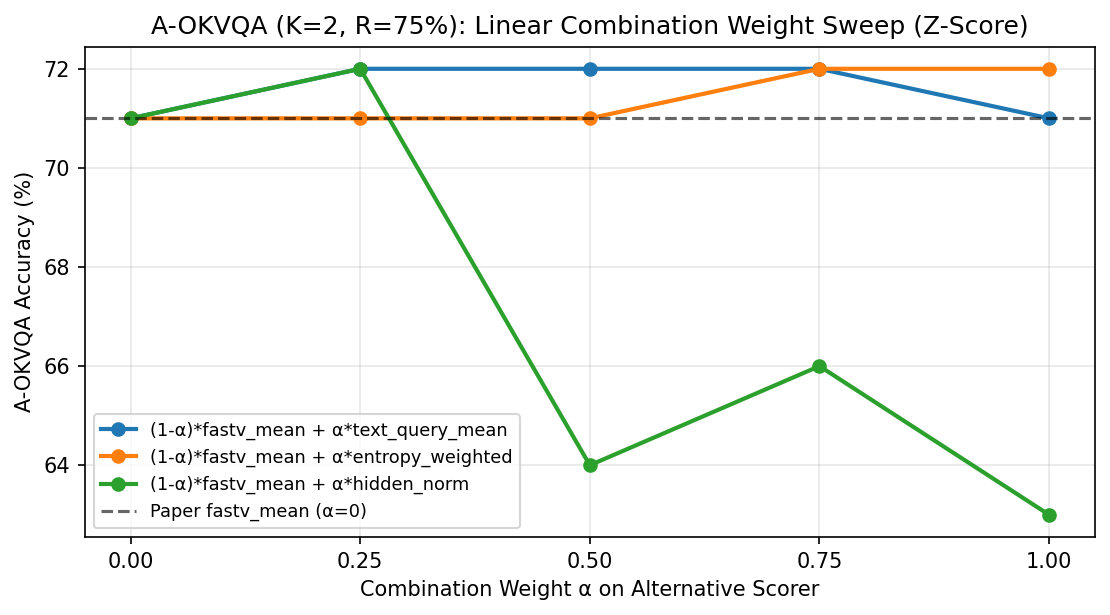

In [12]:
alpha_grid = [0.0, 0.25, 0.50, 0.75, 1.0]
partners = ["text_query_mean", "entropy_weighted", "hidden_norm"]
r_sweep = 0.75

# Reuse endpoints already evaluated in Part 4A where available
endpoint_lookup = (
    aok_df[(aok_df["K"] == 2) & (aok_df["R (%)"] == round(r_sweep * 100.0, 1))]
    .set_index("Scorer ID")["Accuracy (%)"]
    .to_dict()
)

sweep_rows = []
for partner in partners:
    for alpha in alpha_grid:
        if alpha == 0.0 and "fastv_mean" in endpoint_lookup:
            acc = endpoint_lookup["fastv_mean"]
        elif alpha == 1.0 and partner in endpoint_lookup:
            acc = endpoint_lookup[partner]
        else:
            cfg = FastVConfig(
                use_fastv=True,
                fastv_k=2,
                fastv_r=r_sweep,
                mode="inplace",
                scorer="linear_combination",
                scorer_kwargs={
                    "weights": {"fastv_mean": 1.0 - alpha, partner: alpha},
                    "norm": "zscore",
                },
            )
            acc, _, _, _, _ = eval_aokvqa_single(
                cfg, f"Sweep {1-alpha:.2f}*mean + {alpha:.2f}*{partner}"
            )
            acc = round(acc, 2)
        sweep_rows.append(
            {
                "Partner Scorer": partner,
                "alpha": alpha,
                "Accuracy (%)": acc,
                "Delta vs Pure Paper (alpha=0)": round(acc - endpoint_lookup.get("fastv_mean", acc), 2),
            }
        )

sweep_df = pd.DataFrame(sweep_rows)
display(sweep_df.pivot(index="Partner Scorer", columns="alpha", values="Accuracy (%)"))
sweep_df.to_csv(os.path.join(exp2_dir, "aokvqa_alpha_interpolation.csv"), index=False)

plt.figure(figsize=(7.5, 4.2), dpi=150)
for partner in partners:
    sub = sweep_df[sweep_df["Partner Scorer"] == partner].sort_values("alpha")
    plt.plot(sub["alpha"], sub["Accuracy (%)"], marker="o", linewidth=2, label=f"(1-α)*fastv_mean + α*{partner}")
plt.axhline(endpoint_lookup.get("fastv_mean", 0.0), color="black", linestyle="--", alpha=0.6, label="Paper fastv_mean (α=0)")
plt.title("A-OKVQA (K=2, R=75%): Linear Combination Weight Sweep (Z-Score)")
plt.xlabel("Combination Weight α on Alternative Scorer")
plt.ylabel("A-OKVQA Accuracy (%)")
plt.xticks(alpha_grid)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8.5)
plt.tight_layout()
plt.savefig(os.path.join(exp2_dir, "aokvqa_alpha_sweep.png"), bbox_inches="tight")
plt.show()

---
## Section 5 — Experiment 3: OCR-VQA Hyperparameter & Scorer Ablation (Paper Figure 7)

OCR-VQA requires reading fine-grained text on book covers and is highly sensitive to whether pruned tokens discard title/author characters.
* **Part 5A**: Evaluates **all individual & combined scorers** across pruning ratios $R \in \{25\%, 50\%, 75\%, 87.5\%\}$ at $K=2$ (`mode="mask"`, exact `pycocoevalcap` ROUGE-L with $\beta=1.2$).
* **Part 5B**: Reproduces the **Paper Figure 7 Layer $K$ Ablation** ($K \in \{0, 1, 2, 3, 5\}$) at $R=50\%$ and $R=75\%$, comparing **Original Paper (`fastv_mean`)** against top individual and combined scorers (reusing cached $K=0$ and $K=2$ runs automatically).

In [13]:
from FastV.inference.eval.inference_ocrvqa import clean_text as ocr_clean_text, load_ocrvqa_samples

exp3_dir = os.path.join(OUTPUT_ROOT, "exp3_ocrvqa")
os.makedirs(exp3_dir, exist_ok=True)

print(f"Streaming OCR-VQA test samples (max_examples={OCRVQA_MAX_EXAMPLES}, max_questions={OCRVQA_MAX_QUESTIONS})...")
ocr_images, ocr_prompts, ocr_labels = load_ocrvqa_samples(
    max_examples=OCRVQA_MAX_EXAMPLES,
    max_questions=OCRVQA_MAX_QUESTIONS,
)
cleaned_ocr_refs = [[ocr_clean_text(t) for t in ref_list] for ref_list in ocr_labels]
print(f"Loaded {len(ocr_prompts)} OCR-VQA QA pairs.")

_ocr_cache = {}


def eval_ocrvqa_cached(cache_key: tuple, cfg: FastVConfig, desc: str):
    if cache_key in _ocr_cache:
        return _ocr_cache[cache_key]
    controller.update_config(cfg)
    preds, plens, ilens = [], [], []
    t0 = time.perf_counter()
    for prompt, img in tqdm(zip(ocr_prompts, ocr_images), total=len(ocr_prompts), desc=desc, leave=False):
        inp, span = prepare_vlm_inputs(
            processor=processor,
            prompt=prompt,
            image=img,
            device=DEVICE,
            dtype=DTYPE,
            handler=HANDLER,
            include_system_prompt=True,
            image_token_index=IMAGE_TOKEN_INDEX,
        )
        plen = int(inp["input_ids"].shape[1])
        plens.append(plen)
        if span is not None:
            ilens.append(int(span[1]))
        with torch.inference_mode():
            gen = model.generate(
                **inp,
                do_sample=False,
                max_new_tokens=32,
                use_cache=True,
                return_dict_in_generate=True,
            )
        dec = processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip()
        preds.append(dec)
    elapsed = time.perf_counter() - t0
    cleaned_preds = [ocr_clean_text(p) for p in preds]
    avg_rouge, _ = compute_rouge_l(cleaned_ocr_refs, cleaned_preds)
    avg_img = max(1, int(round(np.mean(ilens)))) if ilens else 576
    avg_txt = max(1, int(round(np.mean(plens) - avg_img)))
    res = (round(avg_rouge * 100.0, 2), round(elapsed / max(1, len(preds)), 4), avg_img, avg_txt)
    _ocr_cache[cache_key] = res
    return res


# Evaluate Vanilla Baseline (R = 0%) once
ocr_base_rouge, ocr_base_lat, ocr_avg_img, ocr_avg_txt = eval_ocrvqa_cached(
    ("vanilla", 0, 0.0), FastVConfig(use_fastv=False), "OCR-VQA Baseline (R=0%)"
)
print(f"OCR-VQA Vanilla Baseline (R=0%): ROUGE-L = {ocr_base_rouge:.2f}%")

# Part 5A: All Benchmark Scorers + Random (K=0) across R at K=2
ocr_k2_rows = []
for r in OCRVQA_RS:
    r_pct = round(r * 100.0, 1)
    rnd_score, rnd_lat, _, _ = eval_ocrvqa_cached(
        ("random_k0", 0, r),
        FastVConfig(use_fastv=True, fastv_k=0, fastv_r=r, mode="mask", random_seed=42),
        f"OCR-VQA Random K=0 R={r_pct}%",
    )
    rnd_flops = compute_fastv_flops_ratio(
        NUM_LAYERS, 0, r, ocr_avg_img, ocr_avg_txt, HIDDEN_SIZE, INTERMEDIATE_SIZE, swiglu=IS_SWIGLU
    )
    ocr_k2_rows.append(
        {
            "Scorer ID": "random_k0",
            "Scorer": "Random Pruning (K=0)",
            "Family": "Random Baseline",
            "K": 0,
            "R (%)": r_pct,
            "ROUGE-L (%)": rnd_score,
            "FLOPs (%)": round(rnd_flops["flops_ratio_pct"], 1),
            "Avg Latency (s)": rnd_lat,
        }
    )

    for spec in BENCHMARK_SCORERS:
        cfg = make_scorer_cfg(spec, k=2, r=r, mode="mask")
        sc, lat, _, _ = eval_ocrvqa_cached(
            (spec["id"], 2, r), cfg, f"OCR-VQA {spec['id']} K=2 R={r_pct}%"
        )
        flops = compute_fastv_flops_ratio(
            NUM_LAYERS, 2, r, ocr_avg_img, ocr_avg_txt, HIDDEN_SIZE, INTERMEDIATE_SIZE, swiglu=IS_SWIGLU
        )
        ocr_k2_rows.append(
            {
                "Scorer ID": spec["id"],
                "Scorer": spec["label"],
                "Family": spec["family"],
                "K": 2,
                "R (%)": r_pct,
                "ROUGE-L (%)": sc,
                "FLOPs (%)": round(flops["flops_ratio_pct"], 1),
                "Avg Latency (s)": lat,
            }
        )

ocr_k2_df = pd.DataFrame(ocr_k2_rows)
paper_ocr_by_r = (
    ocr_k2_df[ocr_k2_df["Scorer ID"] == "fastv_mean"].set_index("R (%)")["ROUGE-L (%)"].to_dict()
)
ocr_k2_df["Delta vs Paper fastv_mean (%)"] = ocr_k2_df.apply(
    lambda row: round(row["ROUGE-L (%)"] - paper_ocr_by_r[row["R (%)"]], 2), axis=1
)

print(f"\n=== OCR-VQA ROUGE-L (%) at K=2 Across Scorers (Vanilla Baseline = {ocr_base_rouge:.2f}%) ===")
ocr_k2_pivot = ocr_k2_df.pivot(index="Scorer", columns="R (%)", values="ROUGE-L (%)")
ocr_k2_pivot["Mean ROUGE-L (%)"] = ocr_k2_pivot.mean(axis=1).round(2)
paper_ocr_mean = float(ocr_k2_pivot.loc["Paper: fastv_mean", "Mean ROUGE-L (%)"])
ocr_k2_pivot["Avg Delta vs Paper (%)"] = (ocr_k2_pivot["Mean ROUGE-L (%)"] - paper_ocr_mean).round(2)
ocr_k2_pivot = ocr_k2_pivot.sort_values("Mean ROUGE-L (%)", ascending=False)
display(ocr_k2_pivot)

ocr_k2_df.to_csv(os.path.join(exp3_dir, "ocrvqa_k2_scorer_comparison.csv"), index=False)
ocr_k2_pivot.to_csv(os.path.join(exp3_dir, "ocrvqa_k2_scorer_pivot.csv"))

Streaming OCR-VQA test samples (max_examples=40, max_questions=60)...


README.md:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

Loaded 60 OCR-VQA QA pairs.


OCR-VQA Baseline (R=0%):   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA Vanilla Baseline (R=0%): ROUGE-L = 68.98%


OCR-VQA Random K=0 R=25.0%:   0%|          | 0/60 [00:00<?, ?it/s]

... (41 outputs left out)

OCR-VQA combo_mean_text_norm K=2 R=87.5%:   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA combo_mean_text_norm_minmax K=2 R=87.5%:   0%|          | 0/60 [00:00<?, ?it/s]


=== OCR-VQA ROUGE-L (%) at K=2 Across Scorers (Vanilla Baseline = 68.98%) ===


R (%),25.0,50.0,75.0,87.5,Mean ROUGE-L (%),Avg Delta vs Paper (%)
Scorer,,,,,,
Indiv: entropy_weighted,68.65,67.44,64.74,61.17,65.50,0.11
Paper: fastv_mean,68.65,67.44,64.57,60.88,65.39,0.00
Combo (MinMax): 0.4*mean + 0.35*text_q + 0.25*norm,68.68,67.47,62.72,59.29,64.54,-0.85
Indiv: text_query_mean,68.65,67.44,63.64,57.56,64.32,-1.07
Combo (Z): 0.5*mean + 0.5*text_q,68.65,67.44,61.98,58.67,64.18,-1.21
Combo (Z): 0.4*ent + 0.4*text_q + 0.2*max,68.65,67.44,63.50,56.84,64.11,-1.28
Combo (Z): 0.4*mean + 0.35*text_q + 0.25*norm,68.68,65.80,64.43,57.11,64.01,-1.38
Indiv: fastv_max_head,68.65,67.47,64.51,55.40,64.01,-1.38
Indiv: fastv_mean_std,68.65,67.44,63.86,55.92,63.97,-1.42


In [ ]:
# Part 5B: Paper Figure 7 Pruning Layer K Ablation (K in OCRVQA_KS) at R=50% and R=75%
k_ablation_ids = [
    "fastv_mean",
    "text_query_mean",
    "entropy_weighted",
    "hidden_norm",
    "combo_attn_ensemble",
    "combo_mean_text_norm",
]
k_ablation_specs = [SCORER_BY_ID[sid] for sid in k_ablation_ids if sid in SCORER_BY_ID]
k_ablation_rs = [0.50, 0.75]

ocr_k_rows = []
for spec in k_ablation_specs:
    for r in k_ablation_rs:
        r_pct = round(r * 100.0, 1)
        for k in OCRVQA_KS:
            if k == 0:
                sc, lat, _, _ = eval_ocrvqa_cached(
                    ("random_k0", 0, r),
                    FastVConfig(use_fastv=True, fastv_k=0, fastv_r=r, mode="mask", random_seed=42),
                    f"OCR-VQA Random K=0 R={r_pct}%",
                )
            else:
                cfg = make_scorer_cfg(spec, k=k, r=r, mode="mask")
                sc, lat, _, _ = eval_ocrvqa_cached(
                    (spec["id"], k, r), cfg, f"OCR-VQA {spec['id']} K={k} R={r_pct}%"
                )
            flops = compute_fastv_flops_ratio(
                NUM_LAYERS, k, r, ocr_avg_img, ocr_avg_txt, HIDDEN_SIZE, INTERMEDIATE_SIZE, swiglu=IS_SWIGLU
            )
            ocr_k_rows.append(
                {
                    "Scorer ID": spec["id"],
                    "Scorer": spec["label"],
                    "K": k,
                    "R (%)": r_pct,
                    "ROUGE-L (%)": sc,
                    "FLOPs (%)": round(flops["flops_ratio_pct"], 1),
                    "Avg Latency (s)": lat,
                }
            )

ocr_k_df = pd.DataFrame(ocr_k_rows)
ocr_k_df.to_csv(os.path.join(exp3_dir, "ocrvqa_layer_k_ablation.csv"), index=False)

print("\n=== Paper Fig 7 Layer-K Ablation at R=75% Across Scorers ===")
display(ocr_k_df[ocr_k_df["R (%)"] == 75.0].pivot(index="Scorer", columns="K", values="ROUGE-L (%)"))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.0), dpi=150)

# Plot 1: Paper Fig 7 Layer K ablation at R=50%
for spec in k_ablation_specs:
    sub = ocr_k_df[(ocr_k_df["Scorer ID"] == spec["id"]) & (ocr_k_df["R (%)"] == 50.0)].sort_values("K")
    lw = 2.6 if spec["id"] == "fastv_mean" else 1.9
    ls = "-" if ("combo" in spec["id"] or spec["id"] == "fastv_mean") else "--"
    axes[0].plot(sub["K"], sub["ROUGE-L (%)"], marker="o", linewidth=lw, linestyle=ls, label=spec["id"])
axes[0].axhline(ocr_base_rouge, color="black", linestyle=":", label=f"Vanilla R=0% ({ocr_base_rouge:.1f}%)")
axes[0].set_title("Paper Fig 7 Style: OCR-VQA vs Layer K (R=50%)")
axes[0].set_xlabel("Pruning Layer K (K=0 is Random)")
axes[0].set_ylabel("ROUGE-L (%)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)

# Plot 2: Paper Fig 7 Layer K ablation at R=75%
for spec in k_ablation_specs:
    sub = ocr_k_df[(ocr_k_df["Scorer ID"] == spec["id"]) & (ocr_k_df["R (%)"] == 75.0)].sort_values("K")
    lw = 2.6 if spec["id"] == "fastv_mean" else 1.9
    ls = "-" if ("combo" in spec["id"] or spec["id"] == "fastv_mean") else "--"
    axes[1].plot(sub["K"], sub["ROUGE-L (%)"], marker="s", linewidth=lw, linestyle=ls, label=spec["id"])
axes[1].axhline(ocr_base_rouge, color="black", linestyle=":", label=f"Vanilla R=0% ({ocr_base_rouge:.1f}%)")
axes[1].set_title("Paper Fig 7 Style: OCR-VQA vs Layer K (R=75%)")
axes[1].set_xlabel("Pruning Layer K (K=0 is Random)")
axes[1].set_ylabel("ROUGE-L (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)

# Plot 3: Heatmap of Delta ROUGE-L vs Paper fastv_mean across R at K=2
delta_piv = ocr_k2_df[ocr_k2_df["Scorer ID"] != "random_k0"].pivot(
    index="Scorer ID", columns="R (%)", values="Delta vs Paper fastv_mean (%)"
)
sns.heatmap(delta_piv, annot=True, fmt="+.2f", cmap="RdYlGn", center=0.0, ax=axes[2])
axes[2].set_title("OCR-VQA (K=2): Δ ROUGE-L vs Paper (fastv_mean)")
axes[2].set_xlabel("Pruning Ratio R (%)")
axes[2].set_ylabel("")

plt.tight_layout()
plt.savefig(os.path.join(exp3_dir, "ocrvqa_scorer_ablation_plots.png"), bbox_inches="tight")
plt.show()

OCR-VQA fastv_mean K=1 R=50.0%:   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA fastv_mean K=3 R=50.0%:   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA fastv_mean K=5 R=50.0%:   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA fastv_mean K=1 R=75.0%:   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA fastv_mean K=3 R=75.0%:   0%|          | 0/60 [00:00<?, ?it/s]

OCR-VQA fastv_mean K=5 R=75.0%:   0%|          | 0/60 [00:00<?, ?it/s]

---
## Section 6 — Experiment 4: Multi-Benchmark Evaluation — MME (Table 3), MMMU & Flickr30K (Table 1)

### Part 6A — Multi-Scorer Evaluation at Paper's Canonical Operating Points
Evaluates **Vanilla**, **Original Paper (`fastv_mean`)**, **Individual Scorers**, and **Normalized Linear Combinations** on:
1. **MME Fine-Grained Perception & Cognition (14 Subtasks, Official `Acc + Acc+`)** — compared against both live `fastv_mean` and published Paper `LLaVA-1.5-7B` (`Perception: 1510.8 -> 1511.7`, `Cognition: 348.2 -> 349.3` at `K=3, R=50%`).
2. **MMMU Multi-Discipline Reasoning** — compared against Paper `LLaVA-1.5-7B` (`35.3% -> 35.2%`).
3. **Flickr30K Image Captioning** — ROUGE-L quality & decoding latency speedup.

We test both **$K=3, R=50\%$** (exact setting from the official FastV `lmms-eval` README table!) and **$K=2, R=75\%$** (high-compression regime where scorer quality matters most).

In [ ]:
import ast
import re
from collections import defaultdict
from datasets import load_dataset

exp4_dir = os.path.join(OUTPUT_ROOT, "exp4_multibench")
os.makedirs(exp4_dir, exist_ok=True)

MME_PERCEPTION_TASKS = {
    "existence", "count", "position", "color", "posters",
    "celebrity", "scene", "landmark", "artwork", "OCR",
}
MME_COGNITION_TASKS = {
    "commonsense_reasoning", "numerical_calculation",
    "text_translation", "code_reasoning",
}

# Build multi-benchmark config suite:
#   - Vanilla (100% FLOPs)
#   - All benchmark scorers at K=3, R=50% (matches official FastV README lmms-eval table!)
#   - Core individual + combined scorers at K=2, R=75% (aggressive 64% FLOPs reduction!)
multibench_runs = [("Vanilla", "vanilla", "-", 0.0, FastVConfig(use_fastv=False))]
for spec in BENCHMARK_SCORERS:
    multibench_runs.append(
        (f"{spec['id']} (K=3, R=50%)", spec["id"], 3, 50.0, make_scorer_cfg(spec, 3, 0.50, mode="inplace"))
    )
for sid in ("fastv_mean", "text_query_mean", "entropy_weighted", "hidden_norm", "combo_attn_ensemble", "combo_mean_text_norm"):
    if sid in SCORER_BY_ID:
        spec = SCORER_BY_ID[sid]
        multibench_runs.append(
            (f"{sid} (K=2, R=75%)", sid, 2, 75.0, make_scorer_cfg(spec, 2, 0.75, mode="inplace"))
        )


def eval_mme_scorers(runs):
    print("Loading lmms-lab/MME...")
    mme_ds = load_dataset("lmms-lab/MME", split="test")
    by_cat = defaultdict(list)
    for row in mme_ds:
        by_cat[row["category"]].append(row)

    selected_rows = []
    for cat, items in by_cat.items():
        if MME_MAX_PER_SUBTASK is not None:
            cap = MME_MAX_PER_SUBTASK - (MME_MAX_PER_SUBTASK % 2)
            selected_rows.extend(items[:cap])
        else:
            selected_rows.extend(items)
    print(f"Evaluating {len(selected_rows)} MME questions across {len(by_cat)} subtasks...")

    summary_rows = []
    subtask_records = {}

    for label, sid, k_val, r_pct, cfg in runs:
        controller.update_config(cfg)
        cat_img_results = defaultdict(lambda: defaultdict(list))
        for item in tqdm(selected_rows, desc=f"MME ({label})", leave=False):
            inp, _ = prepare_vlm_inputs(
                processor=processor,
                prompt=item["question"],
                image=item["image"],
                device=DEVICE,
                dtype=DTYPE,
                handler=HANDLER,
                include_system_prompt=True,
                image_token_index=IMAGE_TOKEN_INDEX,
            )
            plen = int(inp["input_ids"].shape[1])
            with torch.inference_mode():
                gen = model.generate(
                    **inp, do_sample=False, max_new_tokens=8, use_cache=True, return_dict_in_generate=True
                )
            raw_pred = processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip().lower()
            pred_yn = "yes" if "yes" in raw_pred[:10] else ("no" if "no" in raw_pred[:10] else raw_pred[:5])
            gt_yn = item["answer"].strip().lower()
            cat_img_results[item["category"]][item["question_id"]].append(int(pred_yn == gt_yn))

        per_scores, cog_scores, cat_table = [], [], {}
        for cat, qid_map in cat_img_results.items():
            all_q = [c for vals in qid_map.values() for c in vals]
            acc = (sum(all_q) / max(1, len(all_q))) * 100.0
            pair_ok = [int(all(v == 1 for v in vals)) for vals in qid_map.values() if len(vals) >= 2]
            acc_plus = (sum(pair_ok) / max(1, len(pair_ok))) * 100.0 if pair_ok else acc
            cat_score = acc + acc_plus
            cat_table[cat] = round(cat_score, 2)
            if cat in MME_PERCEPTION_TASKS:
                per_scores.append(cat_score)
            elif cat in MME_COGNITION_TASKS:
                cog_scores.append(cat_score)

        subtask_records[label] = cat_table
        summary_rows.append(
            {
                "Config": label,
                "Scorer ID": sid,
                "K": k_val,
                "R (%)": r_pct,
                "MME-Perception": round(sum(per_scores), 2),
                "MME-Cognition": round(sum(cog_scores), 2),
                "MME-Total": round(sum(per_scores) + sum(cog_scores), 2),
            }
        )

    df = pd.DataFrame(summary_rows)
    paper_mme_ref = (
        df[df["Scorer ID"] == "fastv_mean"].set_index(["K", "R (%)"])["MME-Total"].to_dict()
    )
    df["Delta Total vs Paper fastv_mean"] = df.apply(
        lambda row: round(row["MME-Total"] - paper_mme_ref[(row["K"], row["R (%)"])], 2)
        if (row["K"], row["R (%)"]) in paper_mme_ref
        else 0.0,
        axis=1,
    )
    return df, pd.DataFrame(subtask_records)


try:
    mme_summary_df, mme_subtasks_df = eval_mme_scorers(multibench_runs)
    print("\n=== MME Multi-Scorer Summary (Published 7B Ref:Per=1510.8->1511.7, Cog=348.2->349.3 at K=3 R=50%) ===")
    display(mme_summary_df)
    mme_summary_df.to_csv(os.path.join(exp4_dir, "mme_scorers_summary.csv"), index=False)
    mme_subtasks_df.to_csv(os.path.join(exp4_dir, "mme_scorers_subtasks.csv"))
except Exception as exc:
    print(f"[WARN] Skipping MME due to dataset load error: {exc}")
    mme_summary_df = pd.DataFrame()

In [ ]:
def eval_mmmu_scorers(runs, max_samples=40):
    print("Loading lmms-lab/MMMU validation subset...")
    ds = load_dataset("lmms-lab/MMMU", split="validation", streaming=True)
    samples = []
    for row in ds:
        if row.get("question_type") == "multiple-choice" and row.get("image_1") is not None:
            opts = row["options"]
            if isinstance(opts, str):
                try:
                    opts = ast.literal_eval(opts)
                except Exception:
                    continue
            if isinstance(opts, list) and len(opts) >= 2:
                samples.append((row["image_1"], row["question"], opts, str(row["answer"]).strip().upper()))
                if len(samples) >= max_samples:
                    break
    print(f"Loaded {len(samples)} MMMU multiple-choice samples.")

    rows = []
    for label, sid, k_val, r_pct, cfg in runs:
        controller.update_config(cfg)
        correct = 0
        for img, q, opts, gt in tqdm(samples, desc=f"MMMU ({label})", leave=False):
            opt_str = " ".join([f"({chr(ord('A') + i)}) {o}" for i, o in enumerate(opts)])
            prompt = (
                f"{q}\nOptions: {opt_str}\n"
                "Answer with the option's letter from the given choices directly."
            )
            inp, _ = prepare_vlm_inputs(
                processor=processor,
                prompt=prompt,
                image=img,
                device=DEVICE,
                dtype=DTYPE,
                handler=HANDLER,
                include_system_prompt=True,
                image_token_index=IMAGE_TOKEN_INDEX,
            )
            plen = int(inp["input_ids"].shape[1])
            with torch.inference_mode():
                gen = model.generate(
                    **inp, do_sample=False, max_new_tokens=4, use_cache=True, return_dict_in_generate=True
                )
            dec = processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip().upper()
            m = re.search(r"\b([A-Z])\b", dec)
            pred = m.group(1) if m else dec[:1]
            correct += int(pred == gt)
        acc = round(100.0 * correct / max(1, len(samples)), 2)
        rows.append({"Config": label, "Scorer ID": sid, "K": k_val, "R (%)": r_pct, "MMMU Acc (%)": acc, "N": len(samples)})

    df = pd.DataFrame(rows)
    paper_ref = df[df["Scorer ID"] == "fastv_mean"].set_index(["K", "R (%)"])["MMMU Acc (%)"].to_dict()
    df["Delta vs Paper fastv_mean (%)"] = df.apply(
        lambda r: round(r["MMMU Acc (%)"] - paper_ref[(r["K"], r["R (%)"])], 2)
        if (r["K"], r["R (%)"]) in paper_ref
        else 0.0,
        axis=1,
    )
    return df


def eval_captioning_scorers(runs, max_samples=25):
    print("Loading lmms-lab/flickr30k test subset for captioning...")
    ds = load_dataset("lmms-lab/flickr30k", split="test", streaming=True)
    samples = []
    for row in ds:
        img = row.get("image")
        caps = row.get("caption") or row.get("captions")
        if img is not None and caps:
            samples.append((img, caps if isinstance(caps, list) else [caps]))
            if len(samples) >= max_samples:
                break
    print(f"Loaded {len(samples)} Flickr30K captioning samples.")

    rows = []
    for label, sid, k_val, r_pct, cfg in runs:
        controller.update_config(cfg)
        preds, lats = [], []
        for img, _ in tqdm(samples, desc=f"Flickr30K ({label})", leave=False):
            inp, _ = prepare_vlm_inputs(
                processor=processor,
                prompt="Provide a one-sentence caption for the provided image.",
                image=img,
                device=DEVICE,
                dtype=DTYPE,
                handler=HANDLER,
                include_system_prompt=True,
                image_token_index=IMAGE_TOKEN_INDEX,
            )
            plen = int(inp["input_ids"].shape[1])
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            with torch.inference_mode():
                gen = model.generate(
                    **inp, do_sample=False, max_new_tokens=32, use_cache=True, return_dict_in_generate=True
                )
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            lats.append(time.perf_counter() - t0)
            preds.append(processor.tokenizer.decode(gen.sequences[0, plen:], skip_special_tokens=True).strip())
        refs = [[c.lower() for c in caps] for _, caps in samples]
        rouge_l, _ = compute_rouge_l(refs, [p.lower() for p in preds])
        rows.append(
            {
                "Config": label,
                "Scorer ID": sid,
                "K": k_val,
                "R (%)": r_pct,
                "Flickr30K ROUGE-L (%)": round(rouge_l * 100.0, 2),
                "Avg Latency (s)": round(float(np.mean(lats)), 4),
                "N": len(samples),
            }
        )

    df = pd.DataFrame(rows)
    paper_ref = df[df["Scorer ID"] == "fastv_mean"].set_index(["K", "R (%)"])["Flickr30K ROUGE-L (%)"].to_dict()
    df["Delta vs Paper fastv_mean (%)"] = df.apply(
        lambda r: round(r["Flickr30K ROUGE-L (%)"] - paper_ref[(r["K"], r["R (%)"])], 2)
        if (r["K"], r["R (%)"]) in paper_ref
        else 0.0,
        axis=1,
    )
    return df


try:
    mmmu_df = eval_mmmu_scorers(multibench_runs, max_samples=MMMU_MAX_SAMPLES)
    print("\n=== MMMU Multi-Scorer Results (Published 7B Ref: 35.3% Vanilla -> 35.2% FastV K=3 R=50%) ===")
    display(mmmu_df)
    mmmu_df.to_csv(os.path.join(exp4_dir, "mmmu_scorers_results.csv"), index=False)
except Exception as exc:
    print(f"[WARN] Skipping MMMU due to dataset load error: {exc}")
    mmmu_df = pd.DataFrame()

try:
    cap_df = eval_captioning_scorers(multibench_runs, max_samples=CAPTION_MAX_SAMPLES)
    print("\n=== Flickr30K Captioning Multi-Scorer Results ===")
    display(cap_df)
    cap_df.to_csv(os.path.join(exp4_dir, "flickr30k_scorers_results.csv"), index=False)
except Exception as exc:
    print(f"[WARN] Skipping Flickr30K due to dataset load error: {exc}")
    cap_df = pd.DataFrame()

### Part 6B — Optional Full `lmms-eval` Harness (GQA, SEED-Bench, Nocaps, COCO-Cap, MMMU, MME)

In [ ]:
if RUN_LMMS_EVAL:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lmms-eval"], check=True)
    lmms_model = "qwen2_5_vl" if "2.5" in MODEL_ID.lower() else ("qwen2_vl" if "qwen2" in MODEL_ID.lower() else "llava_hf")
    subprocess.run(
        [
            "accelerate", "launch", "--num_processes=1", "-m", "lmms_eval",
            "--model", lmms_model,
            "--model_args", f"pretrained={MODEL_ID},attn_implementation=eager",
            "--tasks", "mme,gqa,mmmu_val,seedbench,flickr30k,nocaps",
            "--batch_size", "1",
            "--output_path", os.path.join(OUTPUT_ROOT, "lmms_eval_logs"),
        ],
        check=True,
    )
else:
    print("Skipped full lmms-eval harness (set RUN_LMMS_EVAL = True to run all 9 official lmms-eval tasks).")

---
## Section 7 — Consolidated Master Scorer Leaderboard vs. Original Paper & Verification

Aggregates every benchmark into a single **Master Scorer Leaderboard**, computing:
1. **Per-benchmark scores** and **relative retention (% of Vanilla Baseline)** across A-OKVQA, OCR-VQA, MME, MMMU, and Flickr30K.
2. **Exact $\Delta$ vs. Original Paper Scorer (`fastv_mean`)** across both moderate ($R=50\%$) and high ($R=75\%$) compression.
3. **Side-by-side comparison with Published Paper Numbers** (Chen et al., ECCV 2024 & official `lmms-eval` table), followed by an in-process `R=0` parity check and memory-safe CLI verification.

In [ ]:
# Build Master Cross-Benchmark Scorer Leaderboard
leaderboard_rows = []
_aok_base = float(globals().get("aok_base_acc", 0.0))
_ocr_base = float(globals().get("ocr_base_rouge", 0.0))

aok_50 = aok_df[aok_df["R (%)"] == 50.0].set_index("Scorer ID")["Accuracy (%)"].to_dict() if "aok_df" in globals() else {}
aok_75 = aok_df[aok_df["R (%)"] == 75.0].set_index("Scorer ID")["Accuracy (%)"].to_dict() if "aok_df" in globals() else {}
ocr_50 = ocr_k2_df[ocr_k2_df["R (%)"] == 50.0].set_index("Scorer ID")["ROUGE-L (%)"].to_dict() if "ocr_k2_df" in globals() else {}
ocr_75 = ocr_k2_df[ocr_k2_df["R (%)"] == 75.0].set_index("Scorer ID")["ROUGE-L (%)"].to_dict() if "ocr_k2_df" in globals() else {}

mme_50 = (
    mme_summary_df[(mme_summary_df["K"] == 3) & (mme_summary_df["R (%)"] == 50.0)]
    .set_index("Scorer ID")["MME-Total"]
    .to_dict()
    if ("mme_summary_df" in globals() and not mme_summary_df.empty)
    else {}
)
mmmu_50 = (
    mmmu_df[(mmmu_df["K"] == 3) & (mmmu_df["R (%)"] == 50.0)]
    .set_index("Scorer ID")["MMMU Acc (%)"]
    .to_dict()
    if ("mmmu_df" in globals() and not mmmu_df.empty)
    else {}
)
cap_50 = (
    cap_df[(cap_df["K"] == 3) & (cap_df["R (%)"] == 50.0)]
    .set_index("Scorer ID")["Flickr30K ROUGE-L (%)"]
    .to_dict()
    if ("cap_df" in globals() and not cap_df.empty)
    else {}
)

mme_base = (
    float(mme_summary_df[mme_summary_df["Scorer ID"] == "vanilla"]["MME-Total"].iloc[0])
    if ("mme_summary_df" in globals() and not mme_summary_df.empty)
    else None
)
mmmu_base = (
    float(mmmu_df[mmmu_df["Scorer ID"] == "vanilla"]["MMMU Acc (%)"].iloc[0])
    if ("mmmu_df" in globals() and not mmmu_df.empty)
    else None
)
cap_base = (
    float(cap_df[cap_df["Scorer ID"] == "vanilla"]["Flickr30K ROUGE-L (%)"].iloc[0])
    if ("cap_df" in globals() and not cap_df.empty)
    else None
)

for spec in BENCHMARK_SCORERS:
    sid = spec["id"]
    retentions = []
    if sid in aok_50 and _aok_base > 0:
        retentions.append(100.0 * aok_50[sid] / _aok_base)
    if sid in aok_75 and _aok_base > 0:
        retentions.append(100.0 * aok_75[sid] / _aok_base)
    if sid in ocr_50 and _ocr_base > 0:
        retentions.append(100.0 * ocr_50[sid] / _ocr_base)
    if sid in ocr_75 and _ocr_base > 0:
        retentions.append(100.0 * ocr_75[sid] / _ocr_base)
    if sid in mme_50 and mme_base:
        retentions.append(100.0 * mme_50[sid] / mme_base)
    if sid in mmmu_50 and mmmu_base:
        retentions.append(100.0 * mmmu_50[sid] / mmmu_base)
    if sid in cap_50 and cap_base:
        retentions.append(100.0 * cap_50[sid] / cap_base)

    avg_ret = round(float(np.mean(retentions)), 2) if retentions else 0.0
    leaderboard_rows.append(
        {
            "Scorer ID": sid,
            "Family": spec["family"],
            "A-OKVQA R=50%": aok_50.get(sid),
            "A-OKVQA R=75%": aok_75.get(sid),
            "OCR-VQA R=50%": ocr_50.get(sid),
            "OCR-VQA R=75%": ocr_75.get(sid),
            "MME-Total (K=3 R=50%)": mme_50.get(sid),
            "MMMU Acc (K=3 R=50%)": mmmu_50.get(sid),
            "Flickr30K (K=3 R=50%)": cap_50.get(sid),
            "Avg Retention vs Vanilla (%)": avg_ret,
        }
    )

leaderboard_df = pd.DataFrame(leaderboard_rows)
paper_ret = float(
    leaderboard_df[leaderboard_df["Scorer ID"] == "fastv_mean"]["Avg Retention vs Vanilla (%)"].iloc[0]
)
leaderboard_df["Net Retention Gain vs Paper (%)"] = (
    leaderboard_df["Avg Retention vs Vanilla (%)"] - paper_ret
).round(2)
leaderboard_df = leaderboard_df.sort_values("Avg Retention vs Vanilla (%)", ascending=False).reset_index(drop=True)

print("=" * 92)
print(f"MASTER SCORER LEADERBOARD vs. ORIGINAL FASTV PAPER ({MODEL_ID}, {QUANTIZATION}, mode={RUN_MODE})")
print("=" * 92)
display(leaderboard_df)

print("\n=== Published Paper Reference (LLaVA-1.5-7B Official lmms-eval Table: Vanilla vs FastV K=3 R=50%) ===")
paper_lmms_df = pd.DataFrame(PAPER_REFERENCE["llava_7b_lmms_eval"]).T
paper_lmms_df["Published Retention (%)"] = (
    100.0 * paper_lmms_df["Paper FastV K=3 R=50% (57% FLOPs)"] / paper_lmms_df["Baseline (100% FLOPs)"]
).round(2)
display(paper_lmms_df)

plt.figure(figsize=(10.5, 4.8), dpi=150)
colors = [
    "#111111" if fam == "Paper Baseline"
    else ("#7b2cbf" if "Linear Combo" in fam else "#2b6cb0")
    for fam in leaderboard_df["Family"]
]
bars = plt.barh(leaderboard_df["Scorer ID"][::-1], leaderboard_df["Net Retention Gain vs Paper (%)"][::-1], color=colors[::-1])
plt.axvline(0.0, color="black", linewidth=1.2)
plt.title("Overall Multi-Benchmark Retention Gain/Loss vs Original Paper Scorer (fastv_mean)")
plt.xlabel("Average % Baseline Retention Delta vs fastv_mean (Higher is Better)")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, "master_scorer_leaderboard.png"), bbox_inches="tight")
plt.show()

leaderboard_df.to_csv(os.path.join(OUTPUT_ROOT, "master_scorer_leaderboard.csv"), index=False)

summary_payload = {
    "run_mode": RUN_MODE,
    "model_id": MODEL_ID,
    "handler": HANDLER.name,
    "quantization": QUANTIZATION,
    "gpu_memory_gib": round(GPU_MEM_GIB, 2),
    "paper_reference": PAPER_REFERENCE,
    "master_leaderboard": leaderboard_df.to_dict(orient="records"),
    "exp0_demo": demo_df.to_dict(orient="records") if "demo_df" in globals() else [],
    "exp2_aokvqa": aok_df.to_dict(orient="records") if "aok_df" in globals() else [],
    "exp2_alpha_sweep": sweep_df.to_dict(orient="records") if "sweep_df" in globals() else [],
    "exp3_ocrvqa_k2": ocr_k2_df.to_dict(orient="records") if "ocr_k2_df" in globals() else [],
    "exp3_ocrvqa_layer_k": ocr_k_df.to_dict(orient="records") if "ocr_k_df" in globals() else [],
    "exp4_mme": mme_summary_df.to_dict(orient="records") if ("mme_summary_df" in globals() and not mme_summary_df.empty) else [],
    "exp4_mmmu": mmmu_df.to_dict(orient="records") if ("mmmu_df" in globals() and not mmmu_df.empty) else [],
    "exp4_flickr30k": cap_df.to_dict(orient="records") if ("cap_df" in globals() and not cap_df.empty) else [],
}
summary_path = os.path.join(OUTPUT_ROOT, "scorer_comparison_summary.json")
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary_payload, f, indent=2)
print(f"Saved complete JSON results to: {summary_path}")

In [ ]:
# 1. In-process R=0.0 (force_slice_at_r0=True) exact parity verification before releasing GPU memory
controller.update_config(FastVConfig(use_fastv=False))
with torch.inference_mode():
    vanilla_gen = model.generate(**demo_inputs, max_new_tokens=32, do_sample=False, use_cache=True)

controller.update_config(
    FastVConfig(
        use_fastv=True,
        fastv_k=2,
        fastv_r=0.0,
        mode="inplace",
        scorer="combo_mean_text_norm",
        force_slice_at_r0=True,
    )
)
with torch.inference_mode():
    r0_gen = model.generate(**demo_inputs, max_new_tokens=32, do_sample=False, use_cache=True)

exact_match = torch.equal(vanilla_gen, r0_gen)
print(f"[Parity Check] Vanilla vs FastV combo_mean_text_norm (K=2, R=0.0, force_slice_at_r0=True): {exact_match}")

# 2. Thoroughly release all CUDA tensor references (prevents subprocess OOM in FP16 on 22 GiB L4)
for _var in ("vanilla_gen", "r0_gen", "demo_inputs", "gen", "inp", "model", "processor", "controller"):
    if _var in globals():
        del globals()[_var]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free_gib = torch.cuda.mem_get_info()[0] / (1024 ** 3)
    print(f"GPU memory freed cleanly — available VRAM for standalone CLI check: {free_gib:.2f} GiB")
else:
    free_gib = 0.0

# 3. Verify standalone demo-hf.py CLI using our combined scorer (--scorer combo_mean_text_norm)
cli_quant = "none" if (QUANTIZATION in ("fp16", "none") and free_gib >= 15.5) else "4bit"
!FASTV_MODEL_SIZE={MODEL_SIZE} python demo-hf.py --quantization {cli_quant} --scorer combo_mean_text_norm --fastv-k 2 --fastv-r 0.5 --max-new-tokens 80 --min-new-tokens 80 --compare-baseline --no-stream